<!-- dads-lab-header -->
<div style="background: linear-gradient(135deg, #001a70 0%, #0055d4 100%); color: white; padding: 25px; text-align: center; border-radius: 10px; margin-bottom: 20px;">
  <h1 style="font-size: 30px; margin-bottom: 8px;">Boston 311 Crew Staffing</h1>
  <p style="margin: 0; font-size: 16px;">Hackathon Project: Month-by-Month Crew Planning for the City of Boston</p>
  <p style="margin: 8px 0 0 0; font-size: 14px; opacity: 0.85;">Gqwetha Ncube · DADS 5250 Generative AI in Practice</p>
</div>

### The Problem: Crews Are Committed a Month Before the Work Appears

Boston 311 takes service requests from residents and city workers and routes each one to the department that does the work. 4 departments handle the bulk of it, and every request has a target date the city scores as **ONTIME** or **OVERDUE**.

The work is done by crews, and crews are the expensive part. A crew is paid a full salary whether or not there is work for it. **Hiring takes a month of lead time**, which means a department cannot staff up in the month the work appears. **Releasing takes a month of notice and costs a quarter of the annual salary.** Parks alone may take seasonal crews from April through October at a 30% premium, with no hiring delay and no release cost.

Missing a target date costs money: **20 USD per request not closed on time**, and **another 100 USD once a request passes 30 days beyond target**.

Too few crews produces penalties. Too many produces salary paid for idle capacity. Demand is seasonal, differs sharply by department, and the hiring lead time means next month's crews are committed using this month's information.

> **The question this notebook answers:** how many crews should each department carry in each month of 2025, and what does that plan cost compared with holding January's crew counts unchanged all year.

---

### The 4 Departments

| Department | Work | 2024 requests | On time 2024 | Crew capacity | Annual cost per crew (USD) | Crews Jan 2025 |
|---|---|---|---|---|---|---|
| **PWDx** | Public Works: streets, sidewalks, trash, street lights | 157,610 | 90% | 12 / day | 130,000 | 50 |
| **BTDT** | Transportation: parking, signals, signs | 81,447 | 50% | 15 / day | 110,000 | 18 |
| **PARK** | Parks and Recreation: trees, parks, playgrounds | 18,736 | 93% | 6 / day | 120,000 | 10 |
| **ISD** | Inspectional Services: housing, sanitation, permits | 18,624 | 72% | 4 / day | 140,000 | 16 |

21 working days per month.

---

### The 4 Techniques in Use

| Technique | What It Does in This Notebook |
|---|---|
| **1. Prompt Engineering** | A classification prompt that constrains the model to Boston's own request types and forbids inventing one, measured across 4 context conditions: no type list, a retrieved list of 8, a widened list of 24, and all 150 types in the prompt. |
| **2. Structured Output (Pydantic)** | A strict schema requiring `request_type`, `queue` and `department`, validated with `llm.with_structured_output()`, which keeps an out-of-range department from reaching the cost model. |
| **3. RAG (Chroma + Embeddings)** | Retrieves candidate request types from the de-duplicated list the city uses, built from the `type` and `queue` columns of the 311 data itself. |
| **4. Controllable Agents (LangGraph)** | When the returned type is not in the taxonomy, a conditional edge routes the state into a bounded re-retrieval at higher `k` before the answer is accepted. |

> `staffing.py` has no LLM in it. The crew planning is arithmetic on a forecast, and LangChain is built for pipelines with multiple steps, memory or branching, none of which the cost model has.

---

### 5 Experiments

1. **Measured routing accuracy, split by difficulty.** 60 labeled resident messages, 13 PWDx, 16 BTDT, 16 PARK and 15 ISD, 40 of them clear and 20 written to fall between 2 departments. A single blended accuracy figure would not separate the 2.
2. **Runtime agentic decisions.** LangGraph re-retrieves only when the first answer falls outside the taxonomy, and the routing condition is a checkable membership test rather than a confidence score the model invented.
3. **A baseline without retrieval.** The same 60 messages with the type list removed. The ungrounded model names request types that exist in no city queue.
4. **A forecast with a measured error.** No step that builds the forecast reads the 2025 file. It is used at the end to measure how far the forecast was from what Boston recorded, and to price that error in crews and dollars.
5. **A check on who gets served.** Requests logged by residents against requests logged by city staff, and on-time rates across 19 neighborhoods, to test whether the spread between neighborhoods is service or department mix.

---

### How the Intake Assistant and the Staffing Model Connect

The intake assistant decides which department a request goes to. The staffing model decides how many crews each department needs. They are the same problem seen from 2 ends. A misrouted request is a unit of demand at the wrong department. It adds work to a department that was not staffed for it and removes work from one that was, which changes both crew counts and both overdue bills. The confusion matrix measured in experiment 1 is applied to the 2025 forecast, the staffing model is re-run on that distorted demand, and the difference is reported in crews and in dollars.

In [1]:
# === Shared lab setup: install dads5250 + load API key + sticky pill ===
import os
import importlib.util
if importlib.util.find_spec("dads5250") is None:
    %pip install -q dads5250==0.3.0

from dads5250 import (
    pp,
    pretty_print,
    lab_pill,
    setup_openai,
    setup_gemini,
    DEFAULT_CHAT_MODEL,   # newest reasoning model that supports temperature
    DEFAULT_MINI_MODEL,   # newest mini model that supports temperature
    DEFAULT_EMBED_MODEL,  # current embeddings default
    DEFAULT_GEMINI_MODEL, # tracks the latest stable flash
)
try:
    from dads5250 import EMBED_KWARGS
except ImportError:
    EMBED_KWARGS = {}

lab_pill('Hackathon Project: Boston 311 Crew Staffing')


In [2]:
# === API check: confirm the connection and show the model(s) this project uses ===
client = setup_openai()        # loads OPENAI_API_KEY + verifies it works

pp({
    "OpenAI":       "connected",
    "chat model":   DEFAULT_CHAT_MODEL,
    "mini model":   DEFAULT_MINI_MODEL,
    "embed model":  DEFAULT_EMBED_MODEL,
}, title="API check")


OpenAI ready  |  model: gpt-5.4-mini  |  status: connected


# 1. Load the Boston 311 Data

3 files, one per year, published by the City of Boston under a public domain license.

| File | Role |
|---|---|
| `311_service_requests_2023.csv` | Forecast input |
| `311_service_requests_2024.csv` | Forecast input |
| `311_service_requests_2025.csv` | **Used only for validation, never fitted on.** |

Source: [311 Service Requests, Analyze Boston](https://data.boston.gov/dataset/311-service-requests).
City of Boston, public domain. Downloaded 21 October 2026.

The column names are read off the files before any of the columns are used.

The 3 raw files total about 500 MB and are not distributed with this notebook. Every cell that opens one checks `HAS_RAW` first. Without them the diagnostic cells in this section report that they were skipped, and the cells the later sections depend on read the stored tables under `data/processed/` instead.

| Stored file | Contents |
|---|---|
| `monthly_requests.csv` | Requests, on-time counts and target windows per department per month, 2023 and 2024 |
| `taxonomy.csv` | The 150 de-duplicated request types the assistant chooses from, with department and queue |
| `taxonomy_full.csv` | Every department, queue and request type combination before de-duplication, 1,536 rows |
| `resident_share.csv` | Share of each department's volume reported by residents |
| `forecast_2025.csv` | Monthly 2025 forecast per department |
| `assistant_results.csv` | The 60 test messages with each condition's answer |
| `crew_plan_2025.csv` | The crew plan month by month, with costs |
| `monthly_2025.csv` | Recorded 2025 requests per department per month |
| `origin_summary.csv` | Requests, on-time rates and target windows by origin, 2023 and 2024 |
| `neighborhood_summary.csv` | Resident requests, on-time rates and BTDT share by neighborhood |

Downloading the 3 raw files restores every cell.

In [103]:
# ==========================================================
# Compare the column headers across the three files
# ==========================================================
# Reads 5 rows per file and compares the 3 header lists, before any column name
# is used anywhere else in the notebook.

import pandas as pd
from pathlib import Path

RAW = Path("data/raw")
PROCESSED = Path("data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

FILES = {
    2023: RAW / "311_service_requests_2023.csv",
    2024: RAW / "311_service_requests_2024.csv",
    2025: RAW / "311_service_requests_2025.csv",
}

# The 3 raw files are 159 to 184 MB and are not distributed with this notebook.
# Every cell that opens one is guarded by this flag. The tables under
# data/processed carry what the later sections need.
HAS_RAW = all(p.exists() for p in FILES.values())
print("raw files present:", HAS_RAW)
print()

if HAS_RAW:
    headers = {}
    for year, path in FILES.items():
        head = pd.read_csv(path, nrows=5, low_memory=False)
        headers[year] = list(head.columns)
        print(f"--- {year}: {len(head.columns)} columns ---")
        print(headers[year])
        print()

    base = set(headers[2024])
    for year in [2023, 2025]:
        missing = base - set(headers[year])
        extra = set(headers[year]) - base
        print(f"{year} vs 2024   missing: {sorted(missing)}   extra: {sorted(extra)}")
else:
    print("the header comparison reads the raw files and is skipped")
    
    

raw files present: True

--- 2023: 30 columns ---
['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt', 'on_time', 'case_status', 'closure_reason', 'case_title', 'subject', 'reason', 'type', 'queue', 'department', 'submitted_photo', 'closed_photo', 'location', 'fire_district', 'pwd_district', 'city_council_district', 'police_district', 'neighborhood', 'neighborhood_services_district', 'ward', 'precinct', 'location_street_name', 'location_zipcode', 'latitude', 'longitude', 'geom_4326', 'source']

--- 2024: 30 columns ---
['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt', 'on_time', 'case_status', 'closure_reason', 'case_title', 'subject', 'reason', 'type', 'queue', 'department', 'submitted_photo', 'closed_photo', 'location', 'fire_district', 'pwd_district', 'city_council_district', 'police_district', 'neighborhood', 'neighborhood_services_district', 'ward', 'precinct', 'location_street_name', 'location_zipcode', 'latitude', 'longitude', 'geom_4326', 'source']

--- 2025:

---
**OBSERVATIONS:**

All 3 files have the same 30 columns in the same order. No rename map is needed.

8 of the 30 do the work here:

| Column | What it gives |
|---|---|
| `open_dt` | When the request arrived, which monthly demand is counted on |
| `sla_target_dt` | The date it was due |
| `on_time` | The city's own scoring, ONTIME or OVERDUE |
| `department` | The 4 with crews, and the 13 without |
| `type` | The request type, which the intake assistant classifies into |
| `queue` | The sub-queue inside a department |
| `source` | How it came in, separating resident-reported from employee-logged |
| `neighborhood` | Where it is, for the response-time equity question |

The other 22 are districts, photos, coordinates, geometry, and 2 the crew plan does not need.


In [105]:
# ==========================================================
# Requests by department, 2023 and 2024
# ==========================================================
# Counts requests by department in both years, and separates the 4 departments
# with crews from the rest.

FOUR = ["PWDx", "BTDT", "PARK", "ISD"]

if HAS_RAW:
    counts = {}
    for year in [2023, 2024]:
        col = pd.read_csv(FILES[year], usecols=["department"], low_memory=False)
        counts[year] = col["department"].value_counts()

    by_dept = pd.DataFrame(counts).fillna(0).astype(int)
    by_dept["change"] = by_dept[2024] - by_dept[2023]

    print("all departments:")
    print(by_dept)
    print()
    print("total 2023:", by_dept[2023].sum(), "   total 2024:", by_dept[2024].sum())
    print()
    print("four departments with crews:")
    print(by_dept.loc[FOUR])
    print()
    print("in scope 2023:", by_dept.loc[FOUR, 2023].sum(),
          "   in scope 2024:", by_dept.loc[FOUR, 2024].sum())
else:
    print("the department counts read every row of the raw files and are skipped")
    

all departments:
              2023    2024  change
department                        
ANML           196     185     -11
BHA            134     129      -5
BPD            147     155       8
BTDT         75314   81447    6133
BWSC          3645    3406    -239
DISB            21      34      13
DND             41      43       2
ECON             1       3       2
GEN           7466   10747    3281
GRNi             4       4       0
INFO         11886   12983    1097
ISD          18123   18624     501
ONS             59      75      16
PARK         17541   18736    1195
PROP          1945    2574     629
PWDx        171268  157610  -13658
Test             0       1       1

total 2023: 307791    total 2024: 306756

four departments with crews:
              2023    2024  change
department                        
PWDx        171268  157610  -13658
BTDT         75314   81447    6133
PARK         17541   18736    1195
ISD          18123   18624     501

in scope 2023: 282246    in scope 2

---
**OBSERVATIONS:**

2024 has 306,756 requests across 17 departments. The 4 with crews account for 276,417 of them. The remaining 30,339 belong to 13 departments whose work these crews do not do, the largest being INFO at 12,983 and GEN at 10,747.

Total volume is close to flat between the 2 years, 307,791 and 306,756, however, the mix is not.

| Department | 2023 | 2024 | Change |
|---|---|---|---|
| PWDx | 171,268 | 157,610 | -13,658 |
| BTDT | 75,314 | 81,447 | +6,133 |
| PARK | 17,541 | 18,736 | +1,195 |
| ISD | 18,123 | 18,624 | +501 |

The 2 largest departments moved about 8% in opposite directions. A 2025 forecast built by averaging the 2 years would put PWDx above its 2024 level and BTDT below, which is wrong for both if the movement continues.

Every step from here filters to PWDx, BTDT, PARK and ISD.


---

### Parsing the timestamps

`open_dt` is stored in 2 different ISO 8601 forms within the same column. Pandas' default inference picks one form and fails on the other without raising anything, which is why the aggregation below gives the format explicitly.

In [106]:
# ==========================================================
# Why open_dt needs an explicit format
# ==========================================================
# Reads the column as raw strings and compares what pandas parses by default
# against what it does not.

if HAS_RAW:
    sample = pd.read_csv(FILES[2023], usecols=["open_dt"], low_memory=False, dtype=str)
    parsed = pd.to_datetime(sample["open_dt"], errors="coerce")

    print("total rows:", len(sample))
    print("blank:", sample["open_dt"].isna().sum())
    print("failed to parse:", parsed.isna().sum())
    print()

    print("first ten values as written:")
    print(sample["open_dt"].head(10).tolist())
    print()

    bad = sample.loc[parsed.isna() & sample["open_dt"].notna(), "open_dt"]
    print("ten that failed:")
    print(bad.head(10).tolist())
else:
    print("the parse check reads the 2023 raw file and is skipped")
    


total rows: 307791
blank: 0
failed to parse: 152894

first ten values as written:
['2023-01-02 15:50:52.307', '2023-01-03 11:37:13.827', '2023-01-05 09:51:54.313', '2023-01-06 09:32:10.95', '2023-01-06 11:20:53.71', '2023-01-06 15:57:07.403', '2023-01-09 15:01:42.49', '2023-01-10 21:41:00', '2023-01-15 15:25:04.69', '2023-01-25 08:39:00']

ten that failed:
['2023-01-10 21:41:00', '2023-01-25 08:39:00', '2023-01-27 15:17:00', '2023-01-31 04:25:00', '2023-02-01 11:14:00', '2023-02-10 23:07:00', '2023-02-17 07:54:00', '2023-02-28 18:41:00', '2023-03-08 12:44:00', '2023-03-17 17:56:00']


In [135]:
# ==========================================================
# Aggregate to monthly counts by department
# ==========================================================
# Per department and month:
#   requests         how many arrived
#   ontime           closed by their target date, as the city scored it
#   overdue          closed late, or still open past target
#   no_target        no sla_target_dt, which cannot be scored either way
#   median_sla_days  the typical target window, in days

USE_COLS = ["open_dt", "sla_target_dt", "closed_dt", "on_time", "department"]

if HAS_RAW:
    frames = []
    for year in [2023, 2024]:
        df = pd.read_csv(FILES[year], usecols=USE_COLS, low_memory=False)
        df = df[df["department"].isin(FOUR)].copy()

        # Timestamps are local Boston time and are parsed as written, no timezone
        # shift. The column mixes 2 ISO 8601 forms, with and without
        # milliseconds. The format is given as ISO8601 rather than inferred
        # from the first row.
        df["open_dt"] = pd.to_datetime(df["open_dt"], format="ISO8601", errors="coerce")
        df["sla_target_dt"] = pd.to_datetime(df["sla_target_dt"], format="ISO8601", errors="coerce")

        df["year"] = df["open_dt"].dt.year
        df["month"] = df["open_dt"].dt.month
        df["sla_days"] = (df["sla_target_dt"] - df["open_dt"]).dt.days

        frames.append(df)

    raw = pd.concat(frames, ignore_index=True)

    print("rows after filtering to the four departments:", len(raw))
    print("rows with an unparseable open_dt:", raw["open_dt"].isna().sum())
    print("rows with no sla_target_dt:", raw["sla_target_dt"].isna().sum())
    print()

    monthly = (
        raw
        .groupby(["year", "month", "department"])
        .agg(
            requests=("open_dt", "size"),
            ontime=("on_time", lambda s: (s == "ONTIME").sum()),
            overdue=("on_time", lambda s: (s == "OVERDUE").sum()),
            no_target=("sla_days", lambda s: s.isna().sum()),
            median_sla_days=("sla_days", "median"),
        )
        .reset_index()
    )

    monthly["year"] = monthly["year"].astype(int)
    monthly["month"] = monthly["month"].astype(int)
    monthly.to_csv(PROCESSED / "monthly_requests.csv", index=False)

    print("monthly rows:", len(monthly))
    print(monthly.head(12))
    print(monthly[monthly["year"] == 2024].head(12))

    print()
    print(monthly.groupby(["year", "department"])["requests"].sum().unstack())
else:
    monthly = pd.read_csv(PROCESSED / "monthly_requests.csv")
    print("read the stored monthly table:", monthly.shape)
    print(monthly.columns.tolist())
    print()
    print(monthly.groupby(["year", "department"])["requests"].sum().unstack())



rows after filtering to the four departments: 558663
rows with an unparseable open_dt: 0
rows with no sla_target_dt: 82143

monthly rows: 96
    year  month department  requests  ontime  overdue  no_target  median_sla_days
0   2023      1       BTDT      5692    4926      766        105              1.0
1   2023      1        ISD      1307     977      330         13             30.0
2   2023      1       PARK       765     633      132         13            365.0
3   2023      1       PWDx     12843   11078     1765       3344              2.0
4   2023      2       BTDT      5316    3903     1413        100              1.0
5   2023      2        ISD      1793    1231      562         13             29.0
6   2023      2       PARK       651     530      121         15            365.0
7   2023      2       PWDx      9978    8956     1022       2678              2.0
8   2023      3       BTDT      6889    5586     1303        115              1.0
9   2023      3        ISD      1240   

---
**OBSERVATIONS:**

Parsing `open_dt` with pandas' default inference fails on 152,894 of 307,791 rows in the 2023 file, close to half, with no error raised.

The column mixes 2 ISO 8601 forms, with and without milliseconds: `2023-01-02 15:50:52.307` and `2023-01-10 21:41:00`.

Every value that failed is in the second form. 2 of them, `2023-01-10 21:41:00` and `2023-01-25 08:39:00`, appear in the first 10 values of the column, which means the 2 forms are interleaved rather than separated by year or by department. Giving the format explicitly as `ISO8601` parses both, and the aggregation then reports 0 unparseable dates.

With `errors="coerce"` and no format given, those rows become `NaT` and the aggregation runs on what is left. Every monthly count, every on-time rate and the entire crew plan would have been built on roughly half the data with nothing visibly broken. The count of unparseable dates stays printed rather than being removed once it reads 0.


In [136]:
# ==========================================================
# Target windows and on-time rates by department
# ==========================================================
# median_sla_days varies by department and by month. The staffing model needs
# a target window per department, and the on-time rates are what it has to
# reproduce when run under the crew counts the city actually had.

sla_by_month = monthly.pivot_table(
    index=["year", "month"], columns="department", values="median_sla_days"
)[FOUR]

print("median target window in days, by month")
print(sla_by_month)
print()

ot = (
    monthly
    .groupby(["year", "department"])[["requests", "ontime", "overdue"]]
    .sum()
)
ot["on_time_pct"] = (ot["ontime"] / ot["requests"] * 100).round(1)

print("on-time rate by department and year")
print(ot)


median target window in days, by month
department  PWDx  BTDT   PARK   ISD
year month                         
2023 1       2.0   1.0  365.0  30.0
     2       2.0   1.0  365.0  29.0
     3       2.0   1.0   14.0  30.0
     4       2.0   1.0   10.0  30.0
     5       2.0   1.0  365.0  30.0
     6       2.0   1.0  365.0  30.0
     7       2.0   1.0   14.0  30.0
     8       2.0   1.0  365.0  30.0
     9       3.0   1.0    9.0  43.0
     10      2.0   1.0   10.0  30.0
     11      2.0   1.0   10.0  30.0
     12      2.0   1.0   10.0  30.0
2024 1       2.0   1.0  365.0  30.0
     2       2.0   1.0  365.0  30.0
     3       2.0   1.0  365.0  30.0
     4       2.0   1.0  365.0  30.0
     5       2.0   1.0  365.0  30.0
     6       2.0   1.0  365.0  30.0
     7       2.0   1.0  365.0  30.0
     8       2.0   1.0  365.0  30.0
     9       2.0   1.0  365.0  30.0
     10      2.0   1.0   15.0  30.0
     11      2.0   2.0  365.0  30.0
     12      2.0   1.0  365.0  30.0

on-time rate by departme

---
**OBSERVATIONS:**

Target windows differ by an order of magnitude between departments. PWDx runs 2 days in every month but September 2023, which is 3. BTDT runs 1 day in every month but November 2024, which is 2. ISD is at 30 apart from 29 in February 2023 and 43 in September 2023.

PARK does not settle anywhere. It alternates between 365 and 9 to 15 days, and the pattern differs by year: 365 in 5 of 12 months in 2023, and in 11 of 12 in 2024. A median that moves like that is not describing a typical PARK request.

| Department | 2023 on time | 2024 on time | Volume change |
|---|---|---|---|
| BTDT | 65.2% | 49.9% | +6,133 |
| PARK | 86.8% | 93.2% | +1,195 |
| ISD | 74.4% | 72.4% | +501 |
| PWDx | 90.1% | 89.7% | -13,658 |

BTDT took 8% more volume and lost 15 percentage points of on-time performance. PWDx shed 8% and stayed near 90%.

In [137]:
# ==========================================================
# PARK's two target populations
# ==========================================================
# PARK's monthly median flips between 365 and about 2 weeks, which means the
# median is not describing a typical request. This splits PARK's requests by
# their target window to see the 2 groups.

if HAS_RAW:
    park = raw[raw["department"] == "PARK"].copy()

    print("PARK target windows in days, distribution:")
    print(park["sla_days"].value_counts().head(15))
    print()
    print("share with a target of 365 days:",
          round((park["sla_days"] == 365).sum() / park["sla_days"].notna().sum() * 100, 1), "%")
    print()

    print("same for the other three:")
    for dept in ["PWDx", "BTDT", "ISD"]:
        d = raw[raw["department"] == dept]["sla_days"]
        print(f"{dept}: ", d.value_counts().head(5).to_dict())
else:
    print("the target-window distribution needs every row and is skipped")
    

PARK target windows in days, distribution:
sla_days
365.0    19028
7.0       7176
8.0       2853
1.0       2390
9.0        915
3.0        685
2.0        566
10.0       539
364.0      443
6.0        237
4.0        145
11.0       122
14.0        95
0.0         92
12.0        71
Name: count, dtype: int64

share with a target of 365 days: 53.5 %

same for the other three:
PWDx:  {1.0: 98426, 2.0: 41544, 3.0: 39607, 4.0: 20548, 5.0: 11373}
BTDT:  {1.0: 82915, 3.0: 24402, 2.0: 13608, 14.0: 5670, 4.0: 4666}
ISD:  {30.0: 9111, 120.0: 8683, 2.0: 2730, 720.0: 2479, 90.0: 2085}


---
**OBSERVATIONS:**

Every department has a mixture of target windows, because the window is set by request type rather than by department.

| Department | 5 most common target windows |
|---|---|
| PWDx | 1 day (98,426), 2 (41,544), 3 (39,607), 4 (20,548), 5 (11,373) |
| BTDT | 1 day (82,915), 3 (24,402), 2 (13,608), 14 (5,670), 4 (4,666) |
| ISD | 30 days (9,111), 120 (8,683), 2 (2,730), 720 (2,479), 90 (2,085) |
| PARK | 365 days (19,028), 7 (7,176), 8 (2,853), 1 (2,390), 9 (915) |

PWDx and BTDT are short-target throughout. PARK has 53.5% of its requests at 365 days and most of the rest clustered around a week.

ISD is the one a median describes worst. Its median of 30 days coexists with 120-day and 720-day targets that together outnumber the 30-day ones, 11,162 against 9,111.

A monthly plan can only make a request late if its target falls inside the month it is planning. A 720-day inspection cannot go late within the plan at all.

In [138]:
# ==========================================================
# Split each department-month by whether the target is time-critical
# ==========================================================
# A monthly plan can only make a request late if its target falls inside the
# horizon. Requests with targets of 120, 365 or 720 days absorb backlog for
# longer than the plan runs. This splits each department-month into the share
# whose target is 30 days or less, and the typical window within that share.

CRITICAL_DAYS = 30

if HAS_RAW:
    raw["critical"] = raw["sla_days"] <= CRITICAL_DAYS

    split = (
        raw
        .groupby(["year", "month", "department"])
        .agg(
            requests=("open_dt", "size"),
            scorable=("sla_days", "count"),
            critical=("critical", "sum"),
            critical_window=("sla_days", lambda s: s[s <= CRITICAL_DAYS].median()),
        )
        .reset_index()
    )

    split["critical_share"] = (split["critical"] / split["scorable"]).round(3)
else:
    split = monthly[["year", "month", "department", "requests",
                     "critical_share", "critical_window"]].copy()

print("critical share by department, averaged over the two years")
print(split.groupby("department")[["critical_share", "critical_window"]].mean().round(2).loc[FOUR])
print()
print("critical share by department and year")
print(split.groupby(["year", "department"])["critical_share"].mean().round(3).unstack()[FOUR])


critical share by department, averaged over the two years
            critical_share  critical_window
department                                 
PWDx                  0.98             2.00
BTDT                  0.99             1.04
PARK                  0.46             6.79
ISD                   0.57            18.08

critical share by department and year
department   PWDx   BTDT   PARK    ISD
year                                  
2023        0.982  0.989  0.494  0.558
2024        0.988  0.988  0.421  0.578


---
**OBSERVATIONS:**

Splitting each department-month by whether the target is 30 days or less:

| Department | Share within 30 days | Typical window within that share |
|---|---|---|
| PWDx | 98% | 2.0 days |
| BTDT | 99% | 1.0 days |
| PARK | 46% | 6.8 days |
| ISD | 57% | 18.1 days |

PWDx and BTDT stay within 1 percentage point across the 2 years, and ISD within 2. PARK moves 7, from 0.494 in 2023 to 0.421 in 2024, consistent with its shift toward 365-day targets in the monthly medians.

Fewer than half of PARK's requests and a little over half of ISD's have a target inside a 30-day window. The rest run on horizons longer than any single month of the plan.

`critical_share` and `critical_window` join the monthly file as inputs to the overdue rule.

In [189]:
# ==========================================================
# Does on-time performance move with monthly demand
# ==========================================================
# No crew counts are given for 2023 or 2024. This fixes them at the
# January 2025 levels. Under that assumption utilisation moves only with
# demand, and each department contributes 24 monthly observations.

CAPACITY_PER_DAY = {"PWDx": 12, "BTDT": 15, "PARK": 6, "ISD": 4}
START_CREWS = {"PWDx": 50, "BTDT": 18, "PARK": 10, "ISD": 16}
WORKING_DAYS = 21

m = monthly.copy()
m["capacity"] = m["department"].map(
    lambda d: START_CREWS[d] * CAPACITY_PER_DAY[d] * WORKING_DAYS
)
m["utilisation"] = (m["requests"] / m["capacity"]).round(3)
m["on_time_pct"] = (m["ontime"] / m["requests"] * 100).round(1)

for dept in FOUR:
    d = m[m["department"] == dept]
    corr = d["utilisation"].corr(d["on_time_pct"])
    print(f"{dept}:  utilisation {d['utilisation'].min():.2f} to {d['utilisation'].max():.2f}"
          f"   on-time {d['on_time_pct'].min():.1f} to {d['on_time_pct'].max():.1f}"
          f"   correlation {corr:+.2f}")


PWDx:  utilisation 0.79 to 1.60   on-time 86.1 to 93.7   correlation +0.64
BTDT:  utilisation 0.94 to 1.35   on-time 35.4 to 86.5   correlation -0.31
PARK:  utilisation 0.52 to 2.29   on-time 81.4 to 95.0   correlation +0.33
ISD:  utilisation 0.89 to 1.54   on-time 66.9 to 81.6   correlation -0.35


---
**OBSERVATIONS:**

Holding crew counts at the January 2025 levels, utilisation moves month to month only with demand, giving 24 observations per department.

| Department | Utilisation range | On-time range | Correlation |
|---|---|---|---|
| PWDx | 0.79 to 1.60 | 86.1 to 93.7 | +0.64 |
| BTDT | 0.94 to 1.35 | 35.4 to 86.5 | -0.31 |
| PARK | 0.52 to 2.29 | 81.4 to 95.0 | +0.33 |
| ISD | 0.89 to 1.54 | 66.9 to 81.6 | -0.35 |

PWDx is the only department with a correlation of any size, and it is positive: its busiest months are its best months for on-time performance. The other 3 are weak across 24 observations and run in mixed directions, PARK positive, BTDT and ISD negative, all around 0.3.

Load does not explain on-time performance here. That rules out calibrating the overdue rule against the recorded rates.

In [140]:
 # ==========================================================
# Does the request mix change with volume
# ==========================================================
# PWDx and PARK perform better in their busiest months. If busy months include a
# larger share of short-target work, composition rather than capacity is what
# moves the on-time rate.

def safe_corr(a, b):
    """Correlation is undefined when either series is constant."""
    if a.nunique() < 2 or b.nunique() < 2:
        return "  undefined"
    return f"{a.corr(b):+.2f}"

mix = split.merge(
    monthly[["year", "month", "department", "ontime", "requests"]],
    on=["year", "month", "department"],
    suffixes=("", "_m"),
)
mix["on_time_pct"] = (mix["ontime"] / mix["requests_m"] * 100).round(1)

for dept in FOUR:
    d = mix[mix["department"] == dept]
    print(f"{dept}:"
          f"  volume vs critical_share {safe_corr(d['requests'], d['critical_share'])}"
          f"   volume vs critical_window {safe_corr(d['requests'], d['critical_window'])}"
          f"   critical_window vs on_time {safe_corr(d['critical_window'], d['on_time_pct'])}")


PWDx:  volume vs critical_share -0.19   volume vs critical_window   undefined   critical_window vs on_time   undefined
BTDT:  volume vs critical_share -0.46   volume vs critical_window +0.02   critical_window vs on_time -0.19
PARK:  volume vs critical_share -0.23   volume vs critical_window +0.06   critical_window vs on_time +0.08
ISD:  volume vs critical_share +0.13   volume vs critical_window +0.21   critical_window vs on_time +0.25


---
**OBSERVATIONS:**

The obvious alternative was composition: that busy months include a larger share of short-target work which closes fast. Every correlation tested came back weak, and the strongest of them, BTDT volume against critical share at -0.46, has the wrong sign for that explanation.

PWDx returns `undefined` because its critical window is exactly 2.0 in all 24 months. With no variance, the correlation cannot be computed.

Both hypotheses were tested and neither is supported. Finding the drivers means working at the level of individual request types rather than departments.

In [141]:
# ==========================================================
# Add the target-window split to the monthly file
# ==========================================================

if HAS_RAW:
    monthly = monthly.merge(
        split[["year", "month", "department", "critical_share", "critical_window"]],
        on=["year", "month", "department"],
        how="left",
    )
    monthly.to_csv(PROCESSED / "monthly_requests.csv", index=False)

print(monthly.shape)
print(monthly.columns.tolist())
print(monthly.head())


(96, 10)
['year', 'month', 'department', 'requests', 'ontime', 'overdue', 'no_target', 'median_sla_days', 'critical_share', 'critical_window']
   year  month department  requests  ontime  overdue  no_target  median_sla_days  critical_share  critical_window
0  2023      1       BTDT      5692    4926      766        105              1.0           0.986              1.0
1  2023      1        ISD      1307     977      330         13             30.0           0.566              8.0
2  2023      1       PARK       765     633      132         13            365.0           0.414              7.0
3  2023      1       PWDx     12843   11078     1765       3344              2.0           0.987              2.0
4  2023      2       BTDT      5316    3903     1413        100              1.0           0.992              1.0


---
### What the checks established

The monthly file is verified. Every department total reconciles to the raw files in both years, and the date-parsing fault that silently dropped close to half the rows was caught by a check that stays in the notebook.

2 columns were added that no department-level assumption would have produced: the share of each department-month whose target falls inside a 30-day window, and the typical window within that share. Without them a 720-day ISD inspection would count as overdue in month 2.

Under the rules this problem sets, requests go overdue when capacity falls short. In 2 years of recorded data, on-time rates do not move with load, and at PWDx they move against it.

The crew plan built later answers which schedule minimises cost under the stated rules. It does not predict what Boston's on-time performance would have been.

---

---

## 2. Forecast 2025 Demand

The crew plan needs a monthly demand number for each department in 2025. No forecast of 2025 can be checked against anything, which is why the 2 cells below test methods against 2024 instead, where the answer is known. What those tests show is what builds the 2025 forecast in the third cell.

In [114]:
# ==========================================================
# Can one year predict the next
# ==========================================================
# Two baselines, both using only 2023 and scored against 2024:
# seasonal naive   next year, month m = this year, month m
# flat             next year, month m = this year's monthly average
# If seasonal naive wins, the monthly shape is stable enough to reuse for 2025.

w = monthly.pivot_table(index=["department", "month"], columns="year", values="requests")

rows = []
for dept in FOUR:
    d = w.loc[dept]
    actual, naive, flat = d[2024], d[2023], d[2023].mean()
    rows.append({
        "department": dept,
        "2023": int(d[2023].sum()),
        "2024": int(d[2024].sum()),
        "change %": round((d[2024].sum() / d[2023].sum() - 1) * 100, 1),
        "seasonal naive MAPE": round(((naive - actual).abs() / actual).mean() * 100, 1),
        "flat MAPE": round(((flat - actual).abs() / actual).mean() * 100, 1),
    })

print(pd.DataFrame(rows).to_string(index=False))


department   2023   2024  change %  seasonal naive MAPE  flat MAPE
      PWDx 171268 157610      -8.0                 13.6       14.5
      BTDT  75314  81447       8.1                  7.6       11.2
      PARK  17541  18736       6.8                 17.7       39.8
       ISD  18123  18624       2.8                 13.3       13.9


---
**OBSERVATIONS:**

Seasonal naive beats the flat average for all 4 departments. For PARK it is not close, 17.7 against 39.8. For PWDx and ISD the 2 are within 1 percentage point of each other.

PWDx is the odd one. Its volume dropped 8% between the years, and seasonal naive repeats 2023's level unchanged, which means part of its 13.6 is the level being wrong rather than the shape.

In [115]:
# ==========================================================
# Separating shape error from level error
# ==========================================================
# Seasonal naive repeats 2023's level. Scaling 2023's monthly shape to
# 2024's actual annual total removes the level question and leaves only the
# error in the shape itself.

rows = []
for dept in FOUR:
    d = w.loc[dept]
    actual = d[2024]
    naive = d[2023]
    shape_only = d[2023] / d[2023].sum() * d[2024].sum()

    rows.append({
        "department": dept,
        "seasonal naive MAPE": round(((naive - actual).abs() / actual).mean() * 100, 1),
        "shape only MAPE": round(((shape_only - actual).abs() / actual).mean() * 100, 1),
    })

out = pd.DataFrame(rows)
out["level error"] = (out["seasonal naive MAPE"] - out["shape only MAPE"]).round(1)
print(out.to_string(index=False))


department  seasonal naive MAPE  shape only MAPE  level error
      PWDx                 13.6             10.0          3.6
      BTDT                  7.6              4.5          3.1
      PARK                 17.7             17.2          0.5
       ISD                 13.3             12.6          0.7


---
**OBSERVATIONS:**

Nearly all the error is in the shape. With the annual total known exactly, monthly error still runs from 4.5% at BTDT to 17.2% at PARK. Knowing the level removes 3.6 percentage points of error at PWDx and 3.1 at BTDT, and under 1 at PARK and ISD.

PARK has both the strongest seasonality and the worst shape error, meaning its monthly profile is pronounced but moves between years.

In [116]:
# ==========================================================
# The 2025 forecast
# ==========================================================
# Level: each department keeps its 2024 total. One year-over-year transition
# cannot separate a trend from noise, and the plus or minus 20% sensitivity
# run covers a wider band than the 8% moves seen between 2023 and 2024.
#
# Shape: the average of each department's 2023 and 2024 monthly profiles.
# PARK's shape error of 17.2 shows the profile itself moves between years.

profiles = {}
for dept in FOUR:
    d = w.loc[dept]
    p23 = d[2023] / d[2023].sum()
    p24 = d[2024] / d[2024].sum()
    profiles[dept] = (p23 + p24) / 2

forecast = []
for dept in FOUR:
    level = w.loc[dept][2024].sum()
    for month in range(1, 13):
        forecast.append({
            "year": 2025,
            "month": month,
            "department": dept,
            "requests": int(round(profiles[dept][month] * level)),
        })

forecast_2025 = pd.DataFrame(forecast)
forecast_2025.to_csv(PROCESSED / "forecast_2025.csv", index=False)

print(forecast_2025.pivot_table(index="month", columns="department", values="requests")[FOUR])
print()
print("annual totals:")
print(forecast_2025.groupby("department")["requests"].sum().reindex(FOUR))


department     PWDx    BTDT    PARK     ISD
month                                      
1           12700.0  5888.0   873.0  1417.0
2           10366.0  5851.0   745.0  1564.0
3           12252.0  7329.0  1132.0  1308.0
4           12974.0  6826.0  1404.0  1325.0
5           13691.0  7398.0  2133.0  1490.0
6           13336.0  7201.0  2676.0  1775.0
7           14406.0  6322.0  2548.0  1713.0
8           17505.0  6860.0  2344.0  1924.0
9           16504.0  7704.0  1612.0  1767.0
10          12313.0  7632.0  1306.0  1626.0
11          10521.0  6528.0   900.0  1397.0
12          11040.0  5907.0  1065.0  1319.0

annual totals:
department
PWDx    157608
BTDT     81446
PARK     18738
ISD      18625
Name: requests, dtype: int64


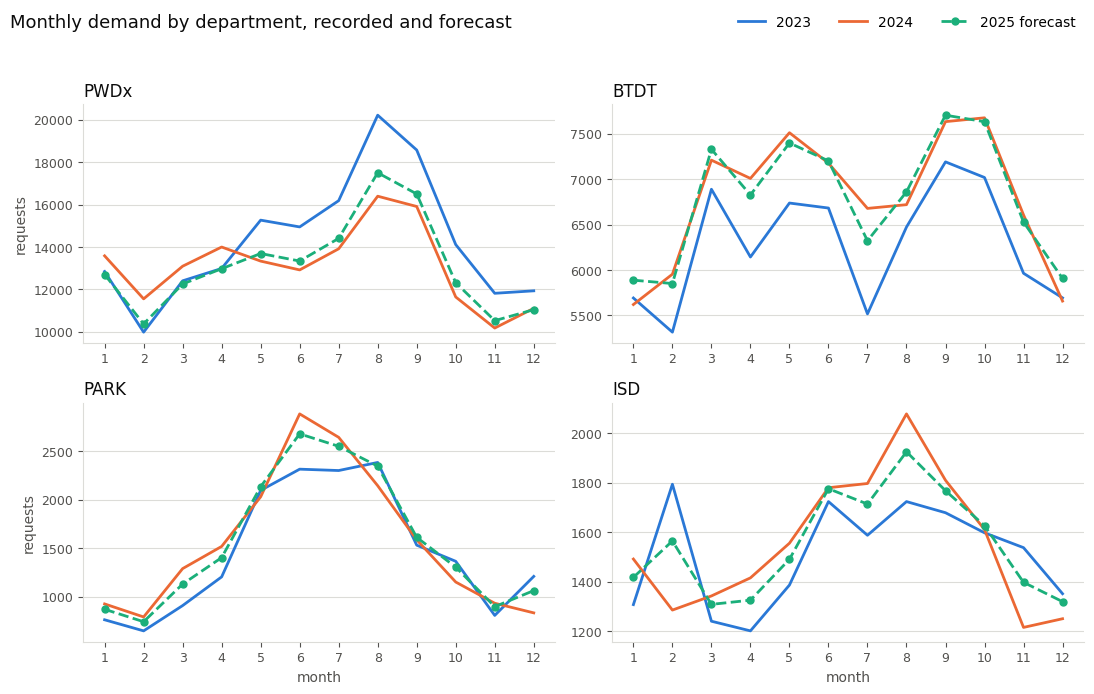

In [117]:
# ==========================================================
# The 2025 forecast against both recorded years
# ==========================================================
# One panel per department, because volumes differ by an order of magnitude
# A shared axis would flatten PARK and ISD against PWDx.

import matplotlib.pyplot as plt

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#dcdcd8"
DEPT_COLOUR = {"PWDx": "#2a78d6", "BTDT": "#eb6834",
               "PARK": "#1baf7a", "ISD": "#eda100"}


def tidy(ax):
    """Recessive grid and axes."""
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=9)


HIST = monthly.pivot_table(index=["department", "month"], columns="year", values="requests")
FC = forecast_2025.pivot_table(index="month", columns="department", values="requests")
months = list(range(1, 13))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, dept in zip(axes.ravel(), FOUR):
    h = HIST.loc[dept].reindex(months)
    ax.plot(months, h[2023], color="#2a78d6", linewidth=2, label="2023")
    ax.plot(months, h[2024], color="#eb6834", linewidth=2, label="2024")
    ax.plot(months, FC[dept].reindex(months), color="#1baf7a", linewidth=2,
            linestyle="--", marker="o", markersize=5, label="2025 forecast")
    ax.set_title(dept, color=INK, fontsize=12, loc="left")
    ax.set_xticks(months)
    tidy(ax)

for ax in axes[1]:
    ax.set_xlabel("month", color=INK_2, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("requests", color=INK_2, fontsize=10)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=10, ncol=3,
           loc="upper right", bbox_to_anchor=(0.99, 0.995))
fig.suptitle("Monthly demand by department, recorded and forecast",
             color=INK, fontsize=13, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


---
**OBSERVATIONS:**

| Department | Low month | High month | Ratio |
|---|---|---|---|
| PARK | 745 (Feb) | 2,676 (Jun) | 3.6x |
| PWDx | 10,366 (Feb) | 17,505 (Aug) | 1.7x |
| BTDT | 5,851 (Feb) | 7,704 (Sep) | 1.3x |
| ISD | 1,308 (Mar) | 1,924 (Aug) | 1.5x |

PARK swings by a factor of 3.6 across the year and 74.8% of its forecast volume falls between April and October. That is the window the problem allows Parks to take seasonal crews in, and the forecast arrives at the same shape from the data alone.

BTDT and ISD are close to flat. Whatever drives their staffing needs, it is not seasonality.

The 2 recorded years separate widely at PWDx and overlap at PARK and ISD, which is the same split the level error measured.



---

## 3. The 311 Intake Assistant

A resident calls 311 and describes a problem in their own words. Someone has to turn "there's a big hole on Centre St near the T stop" into a request type, a queue and a department. Get it wrong and the work arrives at a department that was not staffed for it.

The 311 data contains no free-text resident descriptions, only the categories staff selected. The assistant is built against the category list taken from the data, and measured on a labeled set of resident messages written for this purpose.

3 versions are built and run over the same messages: one with no retrieval at all, one grounded in that category list, and one that re-retrieves when its first answer falls outside it.

In [118]:
# ==========================================================
# Build the request type taxonomy
# ==========================================================
# The list the assistant chooses from comes from the data itself, de-duplicated,
# rather than being written by hand.
#
# Only resident-reported requests are used. Employee-logged entries are written
# in internal shorthand, which would put the reference material in a different
# register from the messages being classified.

import html

TAX_COLS = ["type", "queue", "department", "source"]
RESIDENT_SOURCES = ["Citizens Connect App", "Constituent Call", "Self Service"]

if HAS_RAW:
    tax_frames = []
    for year in [2023, 2024]:
        t = pd.read_csv(FILES[year], usecols=TAX_COLS, low_memory=False)
        t = t[t["department"].isin(FOUR)]
        tax_frames.append(t)

    tax_raw = pd.concat(tax_frames, ignore_index=True)

    print("sources present:")
    print(tax_raw["source"].value_counts())
    print()

    resident = tax_raw[tax_raw["source"].isin(RESIDENT_SOURCES)]
    print("resident-reported rows:", len(resident), "of", len(tax_raw))
    print()

    taxonomy = (
        resident
        .assign(type=lambda d: d["type"].map(lambda s: html.unescape(str(s)).strip()))
        .groupby(["department", "queue", "type"])
        .size()
        .reset_index(name="volume")
        .sort_values(["department", "volume"], ascending=[True, False])
    )

    # The share of each department's volume that reaches it through resident
    # intake. Employee-logged requests enter the work queues directly.
    res_share = (
        tax_raw.assign(is_res=tax_raw["source"].isin(RESIDENT_SOURCES))
        .groupby("department")["is_res"].mean().reindex(FOUR)
    )

    taxonomy.to_csv(PROCESSED / "taxonomy_full.csv", index=False)
    res_share.to_frame("resident_share").to_csv(PROCESSED / "resident_share.csv")
else:
    taxonomy = pd.read_csv(PROCESSED / "taxonomy_full.csv")
    res_share = pd.read_csv(PROCESSED / "resident_share.csv", index_col=0)["resident_share"]
    print("read the stored taxonomy:", taxonomy.shape)
    print()

VALID_TYPES = set(taxonomy["type"])

print("unique request types:", len(VALID_TYPES))
print("type and queue combinations:", len(taxonomy))
print()
print("resident-reported share of volume by department:")
print((res_share * 100).round(1).to_string())
print()
print(taxonomy.groupby("department")["type"].nunique().reindex(FOUR))


sources present:
source
Employee Generated      220487
Citizens Connect App    135687
Constituent Call        123188
City Worker App          59260
Self Service             20039
Maximo Integration           2
Name: count, dtype: int64

resident-reported rows: 278914 of 558663

unique request types: 150
type and queue combinations: 1536

resident-reported share of volume by department:
department
PWDx    54.0
BTDT    39.6
PARK    44.6
ISD     62.5

department
PWDx     90
BTDT     59
PARK     46
ISD     102
Name: type, dtype: int64


In [185]:
# ==========================================================
# One entry per request type, with the department it belongs to
# ==========================================================
# Boston's department assignment follows from the request type. Where a type
# appears under several departments, the one with the most volume is the
# one that handles it; the rest is coding noise or a thin secondary stream.
# Making this a lookup takes a choice away from the model that it has no basis
# for making.

by_type = taxonomy.groupby(["type", "department"], as_index=False)["volume"].sum()
by_type["type_total"] = by_type.groupby("type")["volume"].transform("sum")
by_type["share"] = by_type["volume"] / by_type["type_total"]

dominant = (by_type.sort_values("volume", ascending=False)
            .groupby("type", as_index=False).first())

queues = (taxonomy.sort_values("volume", ascending=False)
          .groupby(["type", "department"], as_index=False).first()[["type", "department", "queue"]])
dominant = dominant.merge(queues, on=["type", "department"], how="left")

TYPE_TO_DEPT = dict(zip(dominant["type"], dominant["department"]))
TYPE_TO_QUEUE = dict(zip(dominant["type"], dominant["queue"]))
VALID_TYPES = set(dominant["type"])

dominant.to_csv(PROCESSED / "taxonomy.csv", index=False)

print("types:", len(dominant))
print()
print("how clear-cut the department is per type:")
print(dominant["share"].describe().round(3))
print()
print("types where the leading department has under 70% of volume:")
print(dominant[dominant["share"] < 0.70][["type", "department", "share", "type_total"]]
      .sort_values("share").to_string(index=False))
print()
print("types by the department that handles them:")
print(dominant["department"].value_counts().reindex(FOUR).to_string())


types: 150

how clear-cut the department is per type:
count    150.000
mean       0.954
std        0.102
min        0.500
25%        0.965
50%        1.000
75%        1.000
max        1.000
Name: share, dtype: float64

types where the leading department has under 70% of volume:
                                    type department    share  type_total
                Sidewalk Cover / Manhole       PWDx 0.500000          10
General Comments For a Program or Policy       PWDx 0.522197        1329
        Parks Lighting/Electrical Issues       PARK 0.525773         485
                  Animal Generic Request       PWDx 0.600000          10
                    BWSC General Request       PWDx 0.600000          10
                  Illegal Auto Body Shop        ISD 0.616279          86
                              Catchbasin       PWDx 0.666667          12
        General Comments For An Employee       PWDx 0.683502         297

types by the department that handles them:
department
PWDx    5

In [142]:
# ==========================================================
# Index the types for retrieval
# ==========================================================
# One document per type. The department is held in metadata and resolved by
# lookup after the model answers, not offered to it as a choice.

from typing import Literal, TypedDict
from pydantic import BaseModel, Field
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langgraph.graph import StateGraph, START, END

tax_docs = [
    Document(
        page_content=f"{r['type']}. {r['queue']}.",
        metadata={"type": r["type"], "queue": r["queue"],
                  "department": r["department"], "volume": int(r["type_total"])},
    )
    for _, r in dominant.iterrows()
]

embedding_model = OpenAIEmbeddings(model=DEFAULT_EMBED_MODEL, **EMBED_KWARGS)
Chroma(collection_name="b311_types", embedding_function=embedding_model).delete_collection()
store = Chroma.from_documents(tax_docs, embedding_model, collection_name="b311_types")

print("documents indexed:", len(tax_docs))
print("documents in the collection:", store._collection.count())
print()

for q in ["there is a deep pothole on my street",
          "no heat in my apartment for four days",
          "a tree limb is hanging over the playground",
          "the fence around the community garden is knocked down"]:
    print(q)
    for d in store.as_retriever(search_kwargs={"k": 3}).invoke(q):
        print("   ", d.metadata["department"], "|", d.metadata["type"])
    print()
    

documents indexed: 150
documents in the collection: 150

there is a deep pothole on my street
    PWDx | Request for Pothole Repair
    PWDx | BWSC Pothole
    PWDx | Catchbasin

no heat in my apartment for four days
    ISD | Heat - Excessive  Insufficient
    ISD | Poor Ventilation
    ISD | Unsatisfactory Utilities - Electrical  Plumbing

a tree limb is hanging over the playground
    PARK | Tree in Park
    PARK | Tree Emergencies
    PARK | Tree Maintenance Requests

the fence around the community garden is knocked down
    PWDx | Street Light Knock Downs
    PARK | Graffiti Removal
    PARK | Planting



---
**OBSERVATIONS:**

The first 3 probes return the types a resident would want. The fourth does not. A knocked-down fence returns `Street Light Knock Downs`, which shares a phrase with the message rather than a subject, and 2 Parks types that describe other work.

In [186]:
# ==========================================================
# Three classifiers
# ==========================================================
# baseline   no retrieval. It has no type list and must guess both the type
#            and the department
# rag        picks a type from the retrieved list. The department is a lookup
# graph      the same and widens retrieval when the model returns NONE or a
#            type that is not in the list
#
# Every model call goes through safe_type or classify_baseline. max_retries on
# the client retries rate limits and transient API errors with backoff, and
# timeout stops a hung call from freezing the run. A call that fails after
# those retries returns NONE, which resolve() turns into an unrouted result,
# and the run continues. An empty message returns NONE before any model call.


BASE_RULES = (
    "Route Boston 311 service requests. "
    "PWDx is Public Works, BTDT is Transportation, "
    "PARK is Parks and Recreation, ISD is Inspectional Services. "
    "Return the request type, the queue and the department."
)

class TypeChoice(BaseModel):
    request_type: str = Field(
        description="exactly one type copied from the candidate list, or NONE if none of them fit")

class Routing(BaseModel):
    request_type: str
    queue: str | None = None
    department: Literal["PWDx", "BTDT", "PARK", "ISD"] | None = None
    routed: bool

class BaselineRouting(BaseModel):
    request_type: str
    queue: str
    department: Literal["PWDx", "BTDT", "PARK", "ISD"]

llm = ChatOpenAI(model=DEFAULT_MINI_MODEL, temperature=0,
                 max_retries=3, timeout=30)

baseline_chain = ChatPromptTemplate.from_messages([
    ("system", BASE_RULES),
    ("human", "{message}"),
]) | llm.with_structured_output(BaselineRouting)

type_chain = ChatPromptTemplate.from_messages([
    ("system",
     "Match a Boston 311 resident message to one request type from the list below. "
     "Copy the type exactly as written. If none of them describe the problem, "
     "return NONE.\n\nCandidates:\n{context}"),
    ("human", "{message}"),
]) | llm.with_structured_output(TypeChoice)

NO_TYPE = "NONE"

def format_candidates(message, k):
    hits = store.as_retriever(search_kwargs={"k": k}).invoke(message)
    return "\n".join(f"- {d.metadata['type']}" for d in hits)

def resolve(t) -> Routing:
    if t in TYPE_TO_DEPT:
        return Routing(request_type=t, queue=TYPE_TO_QUEUE[t],
                       department=TYPE_TO_DEPT[t], routed=True)
    return Routing(request_type=t, routed=False)

def safe_type(message, k):
    """The model's type choice, or NONE when the call cannot be completed.

    Retrieval embeds the query, which is an API call as well, so both are
    inside the same guard.
    """
    if not message or not message.strip():
        return NO_TYPE
    try:
        return type_chain.invoke({
            "message": message,
            "context": format_candidates(message, k),
        }).request_type
    except Exception as err:
        print(f"model call failed, treated as unrouted: {type(err).__name__}")
        return NO_TYPE

def classify_baseline(message):
    if not message or not message.strip():
        return {"request_type": NO_TYPE, "queue": None, "department": None}
    try:
        return baseline_chain.invoke({"message": message}).model_dump()
    except Exception as err:
        print(f"model call failed, treated as unrouted: {type(err).__name__}")
        return {"request_type": NO_TYPE, "queue": None, "department": None}

def classify_rag(message, k=8) -> Routing:
    return resolve(safe_type(message, k))

class RouteState(TypedDict):
    message: str
    k: int
    attempts: int
    result: dict

def classify_node(state):
    t = safe_type(state["message"], state["k"])
    return {**state, "result": resolve(t).model_dump(), "attempts": state["attempts"] + 1}

def widen_node(state):
    return {**state, "k": state["k"] * 3}

def is_known_type(state):
    if state["result"]["routed"]:
        return "accept"
    if state["attempts"] >= 2:
        return "accept"
    return "retry"

g = StateGraph(RouteState)
g.add_node("classify", classify_node)
g.add_node("widen", widen_node)
g.add_edge(START, "classify")
g.add_conditional_edges("classify", is_known_type, {"accept": END, "retry": "widen"})
g.add_edge("widen", "classify")
route_graph = g.compile()

def classify_graph(message, k=8):
    out = route_graph.invoke({"message": message, "k": k, "attempts": 0, "result": {}})
    return out["result"], out["attempts"]


demo = "The fence around the community garden got knocked down on one side."

b = classify_baseline(demo)
r = classify_rag(demo).model_dump()
gr, attempts = classify_graph(demo)

for name, out in [("baseline", b), ("rag", r), ("graph", gr)]:
    print(f"{name:9s} type {out['request_type']!r}")
    print(f"{'':9s} department {out['department']}"
          f"   type in taxonomy: {out['request_type'] in VALID_TYPES}")

print(f"the graph accepted its answer after {attempts} attempt(s)")
print()
print("empty message, no model call:", classify_rag("   ").model_dump()["request_type"])


baseline  type 'Fence down at community garden'
          department PARK   type in taxonomy: False
rag       type 'NONE'
          department None   type in taxonomy: False
graph     type 'NONE'
          department None   type in taxonomy: False
the graph accepted its answer after 2 attempt(s)

empty message, no model call: NONE


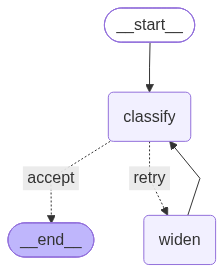

In [187]:
# ==========================================================
# The routing graph
# ==========================================================
# The PNG is saved for the README.

from IPython.display import Image, display

png = route_graph.get_graph().draw_mermaid_png()
with open("routing_graph.png", "wb") as f:
    f.write(png)

display(Image(png))


---
The loop runs at most twice. `classify` retrieves candidate types and asks the model to pick one, or to return NONE if nothing fits. A type that is in the taxonomy resolves to its queue and department by lookup. If nothing was matched, `widen` triples `k` and `classify` runs again against a longer candidate list.

The condition is whether a type was matched, not a score the model produced. A model's own confidence in its answer is not calibrated against anything, and routing on it would mean the graph trusts the same output it is meant to be checking.

Neither the RAG chain nor the graph picks a department. Boston's assignment follows from the request type, which makes it a lookup. The baseline has no type list and has to guess both.

In [49]:
# ==========================================================
# Run all 3 over the 60 labeled messages
# ==========================================================
# Roughly 180 model calls plus retrieval

tests = pd.read_csv("data/test_messages.csv")
print("test messages:", len(tests))

records = []
for i, row in tests.iterrows():
    msg = row["message"]

    b = baseline_chain.invoke({"message": msg}).model_dump()
    r = classify_rag(msg).model_dump()
    gr, attempts = classify_graph(msg)

    records.append({
        "msg_id": row["msg_id"],
        "tier": row["tier"],
        "true_dept": row["true_dept"],
        "baseline_dept": b["department"],
        "baseline_type": b["request_type"],
        "rag_dept": r["department"],
        "rag_type": r["request_type"],
        "graph_dept": gr["department"],
        "graph_type": gr["request_type"],
        "graph_attempts": attempts,
    })

    if (i + 1) % 10 == 0:
        print("done", i + 1, "of", len(tests))

results = pd.DataFrame(records)
results.to_csv(PROCESSED / "assistant_results.csv", index=False)
print()
print(results.head())


test messages: 60
done 10 of 60
done 20 of 60
done 30 of 60
done 40 of 60
done 50 of 60
done 60 of 60

  msg_id   tier true_dept baseline_dept  \
0   m001  clear      PWDx          PWDx   
1   m002  clear      PWDx          PWDx   
2   m003  clear      PWDx          PWDx   
3   m004  clear      PWDx          PWDx   
4   m005  clear      PWDx          PWDx   

                                       baseline_type rag_dept  \
0                                     Pothole Repair     PWDx   
1                                Missed Trash Pickup     PWDx   
2  Recycling missed pickup / overflowing recyclin...     PWDx   
3                                Street Light Outage     PWDx   
4                               Sidewalk Trip Hazard     PWDx   

                                      rag_type graph_dept  \
0                   Request for Pothole Repair       PWDx   
1  Missed Trash/Recycling/Yard Waste/Bulk Item       PWDx   
2  Missed Trash/Recycling/Yard Waste/Bulk Item       PWDx   
3  

In [144]:
# ==========================================================
# Accuracy by difficulty, and where the errors go
# ==========================================================
# Department accuracy overall and split by tier, plus whether the type returned
# exists in the taxonomy.

RUNS = ["baseline", "rag", "graph"]

for run in RUNS:
    results[f"{run}_correct"] = results[f"{run}_dept"] == results["true_dept"]
    results[f"{run}_in_tax"] = results[f"{run}_type"].isin(VALID_TYPES)

acc = pd.DataFrame({
    "overall": [results[f"{r}_correct"].mean() for r in RUNS],
    "clear": [results[results.tier == "clear"][f"{r}_correct"].mean() for r in RUNS],
    "boundary": [results[results.tier == "boundary"][f"{r}_correct"].mean() for r in RUNS],
    "in_taxonomy": [results[f"{r}_in_tax"].mean() for r in RUNS],
}, index=RUNS)

pp({
    r: (f"overall {acc.loc[r,'overall']*100:.1f}%"
        f" | clear {acc.loc[r,'clear']*100:.1f}%"
        f" | boundary {acc.loc[r,'boundary']*100:.1f}%"
        f" | type in taxonomy {acc.loc[r,'in_taxonomy']*100:.1f}%")
    for r in RUNS
}, title="Department accuracy and taxonomy compliance")

for r in ["rag", "graph"]:
    print(f"{r} returned NONE on {(results[f'{r}_type'] == 'NONE').sum()} of {len(results)} messages")
print("the graph widened its search on",
      int((results["graph_attempts"] > 1).sum()), "of", len(results), "messages")
print()

print("confusion matrix, graph run, rows true and columns predicted")
cm = (pd.crosstab(results["true_dept"], results["graph_dept"].fillna("none"))
      .reindex(index=FOUR, columns=FOUR + ["none"], fill_value=0)
      .fillna(0).astype(int))

print(cm)
print()

print("messages the graph got wrong:")
wrong = results[~results["graph_correct"]][["msg_id", "tier", "true_dept", "graph_dept", "graph_type"]].copy()
wrong["graph_dept"] = wrong["graph_dept"].fillna("none")
print(wrong.to_string(index=False))

rag returned NONE on 4 of 60 messages
graph returned NONE on 1 of 60 messages
the graph widened its search on 4 of 60 messages

confusion matrix, graph run, rows true and columns predicted
graph_dept  PWDx  BTDT  PARK  ISD  none
true_dept                              
PWDx          13     0     0    0     0
BTDT           2    13     1    0     0
PARK           2     0    13    0     1
ISD            3     0     0   12     0

messages the graph got wrong:
msg_id     tier true_dept graph_dept                                    graph_type
  m027 boundary      BTDT       PWDx                               Sidewalk Repair
  m028 boundary      BTDT       PWDx Parking on Front/Back Yards (Illegal Parking)
  m030 boundary      BTDT       PARK                            Ground Maintenance
  m035    clear      PARK       PWDx                          BWSC General Request
  m038    clear      PARK       none                                          NONE
  m044 boundary      PARK       PWDx      

---
**OBSERVATIONS:**

| Run | Overall | Clear | Boundary | Type in taxonomy |
|---|---|---|---|---|
| baseline | 83.3% | 97.5% | 55.0% | 1.7% |
| rag | 83.3% | 90.0% | 70.0% | 93.3% |
| graph | 85.0% | 92.5% | 70.0% | 98.3% |

All 4 columns are percentages of the 60 test messages. The first 3 are
department accuracy, split by how hard the message was written to be. The last
is the share of answers naming a request type that exists in Boston's list.

The baseline names a request type Boston's system would accept once in 60
messages. It answers `Pothole Repair` where the type is `Request for Pothole
Repair`, and `Street Light Outage` where it is `Street Light Outages`. Both are
near misses, and neither string exists in the system.

On the easy messages the baseline is the best of these 3, at 97.5%. Potholes are
Public Works and no one needs a type list for that. On the messages written to
fall between 2 departments it drops to 55.0%, while both grounded runs are at
70.0%. That difference is what grounding in Boston's own type list is worth.

On 4 of 60 messages the first answer matched no type, and the graph widened its
search and tried again. That cut unmatched answers from 4 to 1.

Nothing labeled PWDx is routed anywhere else, and the errors from the other 3
departments mostly resolve to PWDx. PWDx handles 57% of the volume across the 4
departments, and where a type is split the lookup sends it to whichever
department handles most of it: 6 of the 8 least clear-cut types resolve to PWDx.

The department is what gets scored, because crews are hired and released by
department. A request routed to the right one is worked by crews that were
planned for it, whichever queue inside it takes the job.

In [125]:
# ==========================================================
# What the model chose on the messages it got wrong
# ==========================================================
# For every message the graph routed to the wrong department, this shows the
# message, the type the model picked, and how the data splits that type across
# departments.

for _, row in results[~results["graph_correct"]].iterrows():
    msg = tests.loc[tests.msg_id == row.msg_id, "message"].iloc[0]
    dest = row.graph_dept if pd.notna(row.graph_dept) else "none"
    print(f"{row.msg_id}  labelled {row.true_dept}, routed {dest}")
    print(f"   message: {msg}")
    print(f"   chose:   {row.graph_type}")
    type_split = by_type[by_type["type"] == row.graph_type][["department", "volume", "share"]]
    if len(type_split):
        print("   data routes this type to:",
              ", ".join(f"{r.department} {r.share:.0%}" for r in type_split.itertuples()))
    print()
    

m027  labelled BTDT, routed PWDx
   message: The blue paint and the wheelchair symbol in the accessible space outside the pharmacy are completely worn away.
   chose:   Sidewalk Repair
   data routes this type to: PWDx 100%

m028  labelled BTDT, routed PWDx
   message: Someone keeps parking fully up on the sidewalk and my mother cannot get her wheelchair past. She has to go into the road.
   chose:   Parking on Front/Back Yards (Illegal Parking)
   data routes this type to: BTDT 25%, ISD 1%, PWDx 74%

m030  labelled BTDT, routed PARK
   message: Cars are parking on the grass strip at the edge of the lot by the field and churning it into mud.
   chose:   Ground Maintenance
   data routes this type to: BTDT 0%, ISD 0%, PARK 97%, PWDx 3%

m035  labelled PARK, routed PWDx
   message: The infield at the baseball field floods after every rain and stays soaked for days. Two games got called off.
   chose:   BWSC General Request
   data routes this type to: BTDT 10%, ISD 30%, PWDx 60%

m038  l

In [62]:
# ==========================================================
# A fourth condition: the whole taxonomy, no retrieval
# ==========================================================
# Retrieval exists to narrow a list too long to show. This taxonomy is 150
# short strings, which fits in a prompt. Putting all of it in front of the
# model removes the failure where the right type was never retrieved, and
# isolates what the retrieval step is contributing.

all_types = "\n".join(f"- {t}" for t in sorted(VALID_TYPES))
print("types in the prompt:", len(VALID_TYPES))
print("approximate prompt length in characters:", len(all_types))
print()

full_list_chain = ChatPromptTemplate.from_messages([
    ("system",
     "Match a Boston 311 resident message to one request type from the list below. "
     "Copy the type exactly as written. If none of them describe the problem, "
     "return NONE.\n\nTypes:\n{context}"),
    ("human", "{message}"),
]) | llm.with_structured_output(TypeChoice)

def classify_full(message) -> Routing:
    return resolve(full_list_chain.invoke({"message": message, "context": all_types}).request_type)

full_rows = []
for i, row in tests.iterrows():
    f = classify_full(row["message"])
    full_rows.append({"msg_id": row["msg_id"], "full_dept": f.department, "full_type": f.request_type})
    if (i + 1) % 20 == 0:
        print("done", i + 1, "of", len(tests))

results = results.drop(columns=[c for c in ["full_dept", "full_type"] if c in results.columns])
results = results.merge(pd.DataFrame(full_rows), on="msg_id", how="left")

print()
print(results[["msg_id", "true_dept", "graph_dept", "full_dept", "full_type"]].head(10).to_string(index=False))


types in the prompt: 150
approximate prompt length in characters: 3924

done 20 of 60
done 40 of 60
done 60 of 60

msg_id true_dept graph_dept full_dept                                   full_type
  m001      PWDx       PWDx      PWDx                  Request for Pothole Repair
  m002      PWDx       PWDx      PWDx Missed Trash/Recycling/Yard Waste/Bulk Item
  m003      PWDx       PWDx      PWDx Missed Trash/Recycling/Yard Waste/Bulk Item
  m004      PWDx       PWDx      PWDx                        Street Light Outages
  m005      PWDx       PWDx      PWDx                             Sidewalk Repair
  m006      PARK       PARK      PARK                            Graffiti Removal
  m007      PWDx       PWDx      PWDx                                  Catchbasin
  m008      PWDx       PWDx      PWDx                    Request for Snow Plowing
  m009      PWDx       PWDx      PWDx                         Pick up Dead Animal
  m010      PWDx       PWDx      PWDx                Requests for

In [126]:
# ==========================================================
# The fourth condition against the other three
# ==========================================================
# Department accuracy overall and split by tier, plus whether the type returned
# exists in the taxonomy.

RUNS = ["baseline", "rag", "graph", "full"]

for run in RUNS:
    results[f"{run}_correct"] = results[f"{run}_dept"] == results["true_dept"]
    results[f"{run}_in_tax"] = results[f"{run}_type"].isin(VALID_TYPES)

acc = pd.DataFrame({
    "overall": [results[f"{r}_correct"].mean() for r in RUNS],
    "clear": [results[results.tier == "clear"][f"{r}_correct"].mean() for r in RUNS],
    "boundary": [results[results.tier == "boundary"][f"{r}_correct"].mean() for r in RUNS],
    "in_taxonomy": [results[f"{r}_in_tax"].mean() for r in RUNS],
}, index=RUNS)

pp({
    r: (f"overall {acc.loc[r,'overall']*100:.1f}%"
        f" | clear {acc.loc[r,'clear']*100:.1f}%"
        f" | boundary {acc.loc[r,'boundary']*100:.1f}%"
        f" | type in taxonomy {acc.loc[r,'in_taxonomy']*100:.1f}%")
    for r in RUNS
}, title="Department accuracy and taxonomy compliance")

for r in ["rag", "graph", "full"]:
    n = (results[f"{r}_type"] == "NONE").sum()
    print(f"{r} returned NONE on {n} of {len(results)} messages")

print("the graph widened its search on",
      int((results["graph_attempts"] > 1).sum()), "of", len(results), "messages")
print()


rag returned NONE on 4 of 60 messages
graph returned NONE on 1 of 60 messages
full returned NONE on 0 of 60 messages
the graph widened its search on 4 of 60 messages



---
**OBSERVATIONS:**

| Run | Overall | Clear | Boundary | Type in taxonomy |
|---|---|---|---|---|
| baseline | 83.3% | 97.5% | 55.0% | 1.7% |
| rag | 83.3% | 90.0% | 70.0% | 93.3% |
| graph | 85.0% | 92.5% | 70.0% | 98.3% |
| full | 90.0% | 97.5% | 75.0% | 100.0% |

The full list is the only condition that names a usable type every time. It is also the one with no retrieval step at all: every type is in front of the model from the start.

That is a result about the size of this taxonomy rather than about retrieval. 150 types come to 3,924 characters, which fits in a prompt. Retrieval exists for lists that do not.

On the messages written to fall between 2 departments the 3 grounded versions run 70.0% to 75.0%, against 55.0% without a type list. On the easy messages the baseline matches the best of them at 97.5%.

The RAG chain left 4 messages unmatched and the graph 1, after widening its search on 4. The full list left none.

Only the department is scored. Crews are hired and released by department, and a request routed to the right one is worked by crews that were planned for it, whichever queue inside it picks up the job.


In [127]:
# ==========================================================
# How much does the answer move between runs
# ==========================================================
# Temperature is 0 and the answers still move. This repeats 4 of the
# classifiers over the same 60 messages 3 times each and records the spread.

def score_once(fn):
    return sum(fn(t["message"]) == t["true_dept"] for _, t in tests.iterrows())

classifiers = {
    "baseline": lambda m: baseline_chain.invoke({"message": m}).department,
    "rag": lambda m: classify_rag(m).department,
    "graph": lambda m: classify_graph(m)[0]["department"],
    "full": lambda m: classify_full(m).department,
}

spread = {}
for name, fn in classifiers.items():
    spread[name] = [score_once(fn) for _ in range(3)]

print(f"{'':10s}" + "".join(f"{'run ' + str(i+1):>9s}" for i in range(3)) + "    % Difference")
for name, scores in spread.items():
    pct = [s / len(tests) * 100 for s in scores]
    print(f"{name:10s}" + "".join(f"{p:>8.1f}%" for p in pct)
          + f"   {max(pct) - min(pct):.1f} %")


              run 1    run 2    run 3    % Difference
baseline      85.0%    85.0%    91.7%   6.7 %
rag           80.0%    81.7%    81.7%   1.7 %
graph         88.3%    88.3%    88.3%   0.0 %
full          88.3%    90.0%    90.0%   1.7 %


---
**OBSERVATIONS:**

| Run Type | Run 1 | Run 2 | Run 3 | % Difference |
|---|---|---|---|---|
| baseline | 85.0% | 85.0% | 91.7% | 6.7 |
| rag | 80.0% | 81.7% | 81.7% | 1.7 |
| graph | 88.3% | 88.3% | 88.3% | 0.0 |
| full | 88.3% | 90.0% | 90.0% | 1.7 |

Department accuracy is the share of the 60 messages routed to the correct department. Temperature is 0 and the answers still move, by as much as 4 messages at the baseline.

The graph returned the same figure 3 times. 3 identical results at 60 messages do not establish that a condition is deterministic, they only bound its variation loosely.

The RAG chain is lowest in all 3 runs. It narrows 150 types down to 8, and when the right type is not among those 8 the model picks the closest of what it was shown, and the lookup assigns that type's department. The graph recovers some of those by widening to 24 and asking again. The full list never runs into it, because nothing is excluded.

The baseline's range covers both the graph and the full list, and for 3 of the 4 conditions the single pass in the accuracy table is outside the range of these repeats. One pass over 60 messages does not separate these conditions on accuracy.

What does separate them is the taxonomy column, and it separates on what each condition is shown rather than on how it performs: the baseline is given no type list, the full condition is given all 150.


---

## 4. The 2025 Crew Plan 

Crews cost a fixed salary whether or not there is work for them. Hiring takes a month of lead time, releasing takes a month of notice and costs a quarter of a year's salary, and Parks alone can take seasonal crews from April through October at a 30% premium with neither delay nor release cost.

A request missing its target date costs 20 USD, and another 100 USD once it passes 30 days beyond target.

3 policies run against the same forecast: holding January's crew counts all year, matching crews to each month's demand, and a smoothed plan that moves by at most 2 crews a month.

---

In [128]:
# ==========================================================
# Load the crew model and the forecast
# ==========================================================
# The rules and the cost arithmetic are in staffing.py next to this notebook
# The sensitivity runs call the same code as the baseline run

import importlib
import staffing
importlib.reload(staffing)

from staffing import (DEPARTMENTS, START_CREWS, CAPACITY_PER_DAY, WORKING_DAYS,
                      ANNUAL_COST, CRITICAL_SHARE, CRITICAL_WINDOW,
                      monthly_capacity, allowed_backlog, crews_needed,
                      demand_from_forecast, simulate, summarise, compare,
                      plan_status_quo, plan_chase, plan_smoothed,
                      scale, spike)

forecast_2025 = pd.read_csv(PROCESSED / "forecast_2025.csv")
demand = demand_from_forecast(forecast_2025)

print("at January crew counts:")
for d in DEPARTMENTS:
    cap = monthly_capacity(d, START_CREWS[d])
    avg = sum(demand[d]) / 12
    print(f"  {d}:  crews {START_CREWS[d]:>3}  capacity {cap:>7,.0f}"
          f"  average demand {avg:>8,.0f}"
          f"  target window {CRITICAL_WINDOW[d]:>4.1f} days"
          f"  work that fits inside it {allowed_backlog(d, START_CREWS[d]):>7,.0f}")


at January crew counts:
  PWDx:  crews  50  capacity  12,600  average demand   13,134  target window  2.0 days  work that fits inside it   1,200
  BTDT:  crews  18  capacity   5,670  average demand    6,787  target window  1.0 days  work that fits inside it     270
  PARK:  crews  10  capacity   1,260  average demand    1,562  target window  6.8 days  work that fits inside it     408
  ISD:  crews  16  capacity   1,344  average demand    1,552  target window 18.1 days  work that fits inside it   1,158


In [129]:
# ==========================================================
# Three policies against the same forecast
# ==========================================================
# hold January permanent crews     leave permanent crew counts where they start
# match demand each month          size crews to each month's forecast
# smoothed, max 2 crews a month    move by at most 2 crews from one month to the next

POLICIES = {
    "hold January permanent crews": plan_status_quo,
    "match demand each month": plan_chase,
    "smoothed, max 2 crews a month": plan_smoothed,
}

policies = compare(demand, POLICIES)
pd.set_option("display.width", 200)

print(policies[["hires", "releases"]].astype(int).to_string())
print()
print((policies[["crew_cost", "severance", "overdue_cost", "total_cost"]] / 1e6)
      .round(2).to_string())
print()
print(policies[["on_time_pct", "on_time_critical_pct"]].round(1).to_string())



                               hires  releases
policy                                        
hold January permanent crews       0         0
match demand each month           72        78
smoothed, max 2 crews a month     25         0

                               crew_cost  severance  overdue_cost  total_cost
policy                                                                       
hold January permanent crews       12.50       0.00          4.28       16.78
match demand each month            13.44       2.46          0.00       15.90
smoothed, max 2 crews a month      14.58       0.00          0.20       14.77

                               on_time_pct  on_time_critical_pct
policy                                                          
hold January permanent crews          62.1                  58.8
match demand each month              100.0                 100.0
smoothed, max 2 crews a month         96.5                  96.1


---
**OBSERVATIONS:**

| Policy | Hires | Releases | Crew cost | Severance | Overdue | Total | On time | On time, critical |
|---|---|---|---|---|---|---|---|---|
| hold January permanent crews | 0 | 0 | 12.50M | 0 | 4.28M | **16.78M** | 62.1% | 58.8% |
| match demand each month | 72 | 78 | 13.44M | 2.46M | 0 | **15.90M** | 100.0% | 100.0% |
| smoothed, max 2 crews a month | 25 | 0 | 14.58M | 0 | 0.20M | **14.77M** | 96.5% | 96.1% |

All figures are in USD. `staffing.py`, the module this notebook imports for the crew arithmetic, defines the hiring lead time, the release notice and cost, the seasonal Parks allowance and the 2 overdue penalties as constants.

Every policy starts January at 50, 18, 10 and 16 crews. Changing January would need a decision taken in December 2024, a month before the plan begins.

Holding January's permanent counts is the most expensive of the 3 while spending the least on crews. Permanent salaries at those counts total 11.92M and seasonal Parks crews add 0.58M, against 4.28M in penalties. The smoothed plan spends 2.08M more on crews and pays 0.20M.

Matching crews to demand every month reaches 100% and costs 1.13M more than the smoothed plan. Its 72 hires and 78 releases cost 2.46M in severance, while the smoothed plan spends 1.14M more on crews and lets none go.

The 2 on-time columns differ because requests with 90, 120, 365 and 720 day targets cannot be late inside a 12-month plan. Under the status quo, 62.1% of all requests finish on time while 58.8% of the work that can be late does.

The smoothed plan is the cheapest of the 3.


In [130]:
# ==========================================================
# The crew table, month by month
# ==========================================================
# Crews by department for every month of 2025, with the hires that get from one
# month to the next.

best = plan_smoothed(demand)
plan_detail = simulate(demand, best)

crew_table = plan_detail.pivot_table(index="month", columns="department", values="crews")[DEPARTMENTS]
seasonal = plan_detail.pivot_table(index="month", columns="department", values="seasonal_crews")["PARK"]
moves = plan_detail.pivot_table(index="month", columns="department", values="hires")[DEPARTMENTS]

print("permanent crews by month")
print(crew_table.astype(int).to_string())
print()
print("seasonal Parks crews by month")
print(seasonal.astype(int).to_string())
print()
print("hires by month")
print(moves.astype(int).to_string())
print()
print("per department over the year")
print(summarise(plan_detail)[["demand", "hires", "releases", "overdue", "on_time_pct", "total_cost"]]
      .round(1).to_string())

plan_detail.to_csv(PROCESSED / "crew_plan_2025.csv", index=False)


permanent crews by month
department  PWDx  BTDT  PARK  ISD
month                            
1             50    18    10   16
2             52    20    12   18
3             54    22    14   20
4             56    24    16   21
5             56    24    18   21
6             56    24    18   21
7             56    24    18   21
8             56    24    18   21
9             56    24    18   21
10            56    24    18   21
11            56    24    18   21
12            56    24    18   21

seasonal Parks crews by month
month
1     0
2     0
3     0
4     0
5     0
6     4
7     3
8     1
9     0
10    0
11    0
12    0

hires by month
department  PWDx  BTDT  PARK  ISD
month                            
1              0     0     0    0
2              2     2     2    2
3              2     2     2    2
4              2     2     2    1
5              0     0     2    0
6              0     0     0    0
7              0     0     0    0
8              0     0     0    0
9         

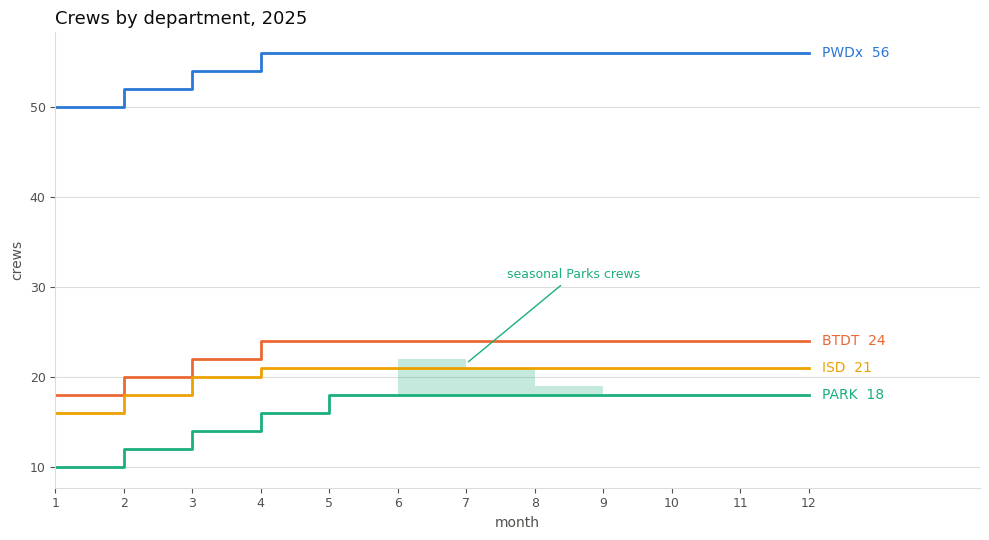

In [131]:
# ==========================================================
# Crews across 2025
# ==========================================================
# A step chart, because a crew count changes at a month boundary and stays
# there until the next decision takes effect. The shaded band on PARK is the
# seasonal crews, which need no hiring delay and no release cost.

fig, ax = plt.subplots(figsize=(10, 5.5))
months = list(range(1, 13))

for dept in DEPARTMENTS:
    y = crew_table[dept].reindex(months)
    ax.step(months, y, where="post", color=DEPT_COLOUR[dept], linewidth=2)
    ax.text(12.2, y.iloc[-1], f"{dept}  {int(y.iloc[-1])}",
            color=DEPT_COLOUR[dept], fontsize=10, va="center")

park_total = (crew_table["PARK"] + seasonal).reindex(months)
ax.fill_between(months, crew_table["PARK"].reindex(months), park_total,
                step="post", color=DEPT_COLOUR["PARK"], alpha=0.25, linewidth=0)
ax.annotate("seasonal Parks crews", xy=(7.0, 21.5), xytext=(7.6, 31),
            color=DEPT_COLOUR["PARK"], fontsize=9,
            arrowprops=dict(arrowstyle="-", color=DEPT_COLOUR["PARK"], linewidth=1))

ax.set_xticks(months)
ax.set_xlim(1, 14.5)
ax.set_xlabel("month", color=INK_2, fontsize=10)
ax.set_ylabel("crews", color=INK_2, fontsize=10)
ax.set_title("Crews by department, 2025", color=INK, fontsize=13, loc="left")
tidy(ax)

fig.tight_layout()
fig.savefig("crew_plan_2025.png", dpi=150)
plt.show()


---
**OBSERVATIONS:**

January runs at the starting counts with no hires anywhere, because a crew for January would have to be ordered in December 2024. The first hires arrive in February.

Hiring runs through months 2 to 4, and into month 5 for Parks. PWDx reaches 56, BTDT 24, PARK 18 and ISD 21, and no department releases a crew all year, which keeps severance at 0.

Every department moves at the policy's limit of 2 crews a month until it reaches its level. The cap binds for all 4, not only the department that finishes short.

Seasonal Parks crews appear in 3 months, 4 in June, 3 in July and 1 in August. From May onward 18 permanent crews clear 2,268 requests a month, which covers every month of the April to October window except the summer peak.

BTDT's 65 overdue requests all fall in March. At 22 crews it clears 6,930 against 7,329 arrivals, and the 399 left waiting are more than the 330 its 1-day target window covers. The April hire that would have closed the difference was ordered in March.

PWDx accounts for 9,733 of the 9,798 overdue requests across the year. At 56 crews it clears 14,112 a month, while the forecast reaches 17,505 in August and 16,504 in September. The smoothed policy settles at a level sized for the year, and the shortfall appears in the summer.

PARK and ISD finish at 100%. Both start the year below their average monthly demand and reach a level that covers it by April.


---

## 5. Sensitivity Analysis

The crew plan is committed before the year starts, built on a forecast with a measured error of 4.5% to 17.2% depending on the department. Demand then arrives at whatever level it arrives at, and a storm can put a month far outside anything the forecast anticipated.

Each scenario is run twice. Once against the committed plan, which cannot change because the crews were already hired, and once against a plan built knowing the true demand. The difference between the 2 is the cost of committing crews before the demand is known.


In [132]:
# ==========================================================
# Demand 20% above and below forecast
# ==========================================================
# The committed plan is the smoothed one built on the forecast. It does not
# change when demand turns out different, because the crews were already hired.
# The perfect columns show what the same policy would have chosen knowing the
# true demand.

rows = []
for factor in [0.8, 0.9, 1.0, 1.1, 1.2]:
    actual = scale(demand, factor)

    committed = summarise(simulate(actual, best)).loc["TOTAL"]
    perfect = summarise(simulate(actual, plan_smoothed(actual))).loc["TOTAL"]

    rows.append({
        "demand": f"{factor:.0%}",
        "committed_cost": committed["total_cost"] / 1e6,
        "committed_on_time": committed["on_time_pct"],
        "perfect_cost": perfect["total_cost"] / 1e6,
        "perfect_on_time": perfect["on_time_pct"],
        "cost_of_error": (committed["total_cost"] - perfect["total_cost"]) / 1e6,
    })

sens = pd.DataFrame(rows).set_index("demand")
print(sens.round(2).to_string())


        committed_cost  committed_on_time  perfect_cost  perfect_on_time  cost_of_error
demand                                                                                 
80%              14.48             100.00         12.42            96.68           2.06
90%              14.54              99.49         13.49            96.01           1.05
100%             14.77              96.46         14.77            96.46           0.00
110%             16.07              76.91         15.87            93.29           0.20
120%             22.21              49.05         18.51            65.25           3.70


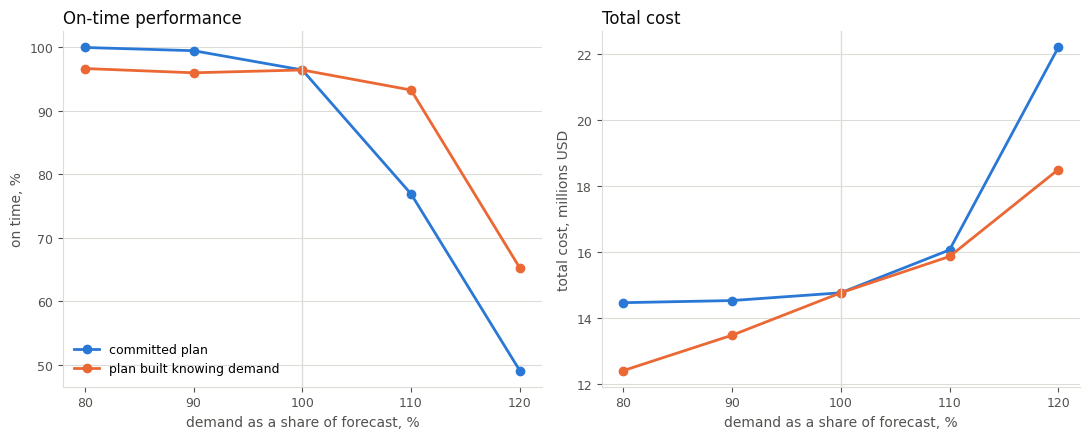

In [133]:
# ==========================================================
# On-time and cost against the demand level
# ==========================================================
# The committed plan cannot change once the crews are hired. The second line is
# the same policy rebuilt knowing the demand that arrived.
#
# Two panels rather than two y-axes on one chart. On-time is a percentage and
# cost is millions of dollars, and a shared axis would put a crossing point on
# screen that means nothing.

COMMITTED, PERFECT = "#2a78d6", "#eb6834"
levels = [80, 90, 100, 110, 120]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(levels, sens["committed_on_time"], color=COMMITTED, linewidth=2,
         marker="o", markersize=6, label="committed plan")
ax1.plot(levels, sens["perfect_on_time"], color=PERFECT, linewidth=2,
         marker="o", markersize=6, label="plan built knowing demand")
ax1.set_ylabel("on time, %", color=INK_2, fontsize=10)
ax1.set_title("On-time performance", color=INK, fontsize=12, loc="left")

ax2.plot(levels, sens["committed_cost"], color=COMMITTED, linewidth=2,
         marker="o", markersize=6)
ax2.plot(levels, sens["perfect_cost"], color=PERFECT, linewidth=2,
         marker="o", markersize=6)
ax2.set_ylabel("total cost, millions USD", color=INK_2, fontsize=10)
ax2.set_title("Total cost", color=INK, fontsize=12, loc="left")

for ax in (ax1, ax2):
    ax.set_xlabel("demand as a share of forecast, %", color=INK_2, fontsize=10)
    ax.set_xticks(levels)
    ax.axvline(100, color=GRID, linewidth=1)
    tidy(ax)

ax1.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()


---
**OBSERVATIONS:**

| Demand | Committed cost | Committed on time | Perfect cost | Perfect on time | Difference |
|---|---|---|---|---|---|
| 80% | 14.48M | 100.0% | 12.42M | 96.7% | 2.06M |
| 90% | 14.54M | 99.5% | 13.49M | 96.0% | 1.05M |
| 100% | 14.77M | 96.5% | 14.77M | 96.5% | 0 |
| 110% | 16.07M | 76.9% | 15.87M | 93.3% | 0.20M |
| 120% | 22.21M | 49.1% | 18.51M | 65.3% | 3.70M |

All figures are in USD.

Over-forecasting and under-forecasting do not cost the same thing. Below the forecast the committed plan costs more than one sized for the demand that arrived, and finishes better on time. Above the forecast it costs more and finishes worse.

The decline starts between the forecast level and 10% above it, where on-time drops by close to 20 percentage points. The committed plan operates near the edge of what its crews can clear at the level it was built for.

At 120%, even a plan built knowing the demand in advance cannot reach it. It starts January at the same crew counts and moves by at most 2 crews a month, and 11 months of that is not enough for 20% more work.

At 110% the plan that knew spends less and finishes 16.4 percentage points higher on time. Hiring earlier is cheaper than paying the penalties that follow from not hiring.

In [134]:
# ==========================================================
# A storm month
# ==========================================================
# A snow event puts a month of Public Works demand far above anything the
# forecast anticipated. Crews cannot be added in the month it arrives, because
# hiring takes a month of lead time.

rows = []
for mult in [1.5, 2.0, 3.0]:
    actual = spike(demand, "PWDx", 2, mult)
    res = summarise(simulate(actual, best))
    rows.append({
        "February PWDx": f"x{mult}",
        "arrivals": actual["PWDx"][1],
        "total_cost": res.loc["TOTAL", "total_cost"] / 1e6,
        "on_time_all": res.loc["TOTAL", "on_time_pct"],
        "PWDx_overdue": res.loc["PWDx", "overdue"],
        "PWDx_on_time": res.loc["PWDx", "on_time_pct"],
    })

print(pd.DataFrame(rows).set_index("February PWDx").round(1).to_string())
print()

feb_crews = best["PWDx"][1]
storm_arrivals = demand["PWDx"][1] * 3
storm_crews = crews_needed("PWDx", storm_arrivals)

annual_capacity = sum(monthly_capacity("PWDx", c) for c in best["PWDx"])
annual_demand = sum(demand["PWDx"])
print(f"PWDx capacity across 2025: {annual_capacity:,.0f}"
      f"   forecast demand: {annual_demand:,.0f}"
      f"   spare: {annual_capacity - annual_demand:,.0f}")

print(f"PWDx February capacity in the plan: {monthly_capacity('PWDx', feb_crews):,.0f}"
      f"  at {feb_crews} crews")
print(f"crews to clear a 3x February within the month: {storm_crews}")
print(f"annual cost at {storm_crews} crews: {storm_crews * ANNUAL_COST['PWDx'] / 1e6:.2f}M"
      f"   at {feb_crews} crews: {feb_crews * ANNUAL_COST['PWDx'] / 1e6:.2f}M")


               arrivals  total_cost  on_time_all  PWDx_overdue  PWDx_on_time
February PWDx                                                               
x1.5            15549.0        14.8         96.1       10979.2          93.3
x2.0            20732.0        15.6         82.9       49111.0          70.8
x3.0            31098.0        19.6         54.6      134943.3          24.3

PWDx capacity across 2025: 166,320   forecast demand: 157,608   spare: 8,712
PWDx February capacity in the plan: 13,104  at 52 crews
crews to clear a 3x February within the month: 124
annual cost at 124 crews: 16.12M   at 52 crews: 6.76M


---
**OBSERVATIONS:**

| February PWDx | Arrivals | Total cost | On time, all | PWDx overdue | PWDx on time |
|---|---|---|---|---|---|
| 1.5x | 15,549 | 14.8M | 96.1% | 10,979 | 93.3% |
| 2x | 20,732 | 15.6M | 82.9% | 49,111 | 70.8% |
| 3x | 31,098 | 19.6M | 54.6% | 134,943 | 24.3% |

All figures are in USD.

PWDx February capacity is 13,104 at 52 crews, against a forecast of 10,366. A 1.5x February arrives above that capacity.

Across 2025 the plan gives PWDx 166,320 of capacity against 157,608 of forecast demand, 8,712 more than the year needs. A 1.5x February adds 5,183 requests, which that spare covers, and PWDx still ends the year above 90%. A 2x February adds 10,366, which it does not, and the overdue count rises by a factor of 4.5 while the extra arrivals only double. A storm month is paid for in the 10 months after it.

Crews cannot be added fast enough to answer the month itself. Clearing a 3x February inside February would take 124 crews against 52, 16.12M a year against 6.76M, and the decision would have to be taken in January, a month before the snow.

---

## 6. The Forecast Against the 2025 Data

`311_service_requests_2025.csv` is the City of Boston's 2025 export of 311 service requests, in the same 30 columns as the 2023 and 2024 files. Nothing above this point reads it. The taxonomy and the forecast were built from the 2023 and 2024 files alone.

This section measures how far the forecast was from the requests Boston recorded in 2025, and what that error cost. The committed crew plan is run against the recorded requests and compared with a plan built knowing them in advance.


In [145]:
# ==========================================================
# Aggregate the 2025 file by month and department
# ==========================================================
# Same parsing as the 2023 and 2024 files: an explicit ISO8601 format

MONTHLY_2025_PATH = PROCESSED / "monthly_2025.csv"

if HAS_RAW:
    df25 = pd.read_csv(FILES[2025], usecols=["open_dt", "department"], low_memory=False)
    df25 = df25[df25["department"].isin(FOUR)].copy()
    df25["open_dt"] = pd.to_datetime(df25["open_dt"], format="ISO8601", errors="coerce")

    print("rows after filtering to the four departments:", len(df25))
    print("rows with an unparseable open_dt:", int(df25["open_dt"].isna().sum()))
    print("years present:",
          df25["open_dt"].dt.year.dropna().astype(int).value_counts().to_dict())
    print()

    df25 = df25[df25["open_dt"].dt.year == 2025]
    df25["month"] = df25["open_dt"].dt.month

    m25 = (
        df25.groupby(["month", "department"])
        .size()
        .unstack("department")
        .reindex(index=range(1, 13), columns=FOUR, fill_value=0)
    )
    m25.to_csv(MONTHLY_2025_PATH)
else:
    m25 = pd.read_csv(MONTHLY_2025_PATH, index_col="month")[FOUR]
    print("read the stored 2025 table:", m25.shape)
    print()

print("2025 recorded requests by month:")
print(m25.to_string())
print()
print("month on month change in the total, %:")
print((m25.sum(axis=1).pct_change() * 100).round(1).to_string())


rows after filtering to the four departments: 244589
rows with an unparseable open_dt: 0
years present: {2025: 244589}

2025 recorded requests by month:
department   PWDx  BTDT  PARK   ISD
month                              
1            9452  6206   687  1331
2           12266  5979   419  1058
3           10403  7344  1092  1333
4           10109  6990  1074  1324
5           10892  7099  1568  1380
6           11411  6872  1950  1778
7           12002  6640  1754  1967
8           14861  6710  2000  1888
9           14041  7856  1531  1815
10           9978  6992  1225  1563
11           8699  6130   350  1371
12           7982  5652   246  1319

month on month change in the total, %:
month
1      NaN
2     11.6
3      2.3
4     -3.3
5      7.4
6      5.1
7      1.6
8     13.8
9     -0.8
10   -21.7
11   -16.2
12    -8.2


In [150]:
# ==========================================================
# Recorded against forecast, month by month
# ==========================================================
# The month on month drops after September, the forecast drops in 
# those months too, because autumn is quieter


fc25 = forecast_2025.pivot_table(index="month", columns="department", values="requests")[FOUR]

compare = pd.DataFrame({
    "forecast": fc25.sum(axis=1).round(0).astype(int),
    "recorded": m25.sum(axis=1),
})
compare["recorded_as_pct_of_forecast"] = (compare["recorded"] / compare["forecast"] * 100).round(1)
print(compare.to_string())


       forecast  recorded  recorded_as_pct_of_forecast
month                                                 
1         20878     17676                         84.7
2         18526     19722                        106.5
3         22021     20172                         91.6
4         22529     19497                         86.5
5         24712     20939                         84.7
6         24988     22011                         88.1
7         24989     22363                         89.5
8         28633     25459                         88.9
9         27587     25243                         91.5
10        22877     19758                         86.4
11        19346     16550                         85.5
12        19331     15199                         78.6


In [151]:
# ==========================================================
# Did the 2025 file stop carrying request types during the year
# ==========================================================
# Fewer distinct types late in the year could just be lower volume. A type with
# 20 or more requests every month from January to September that reads zero is not.

if HAS_RAW:
    t25 = pd.read_csv(FILES[2025], usecols=["open_dt", "department", "type"], low_memory=False)
    t25 = t25[t25["department"].isin(FOUR)].copy()
    t25["open_dt"] = pd.to_datetime(t25["open_dt"], format="ISO8601", errors="coerce")
    t25 = t25.dropna(subset=["open_dt"])
    t25 = t25[t25["open_dt"].dt.year == 2025]
    t25["month"] = t25["open_dt"].dt.month
    t25["type"] = t25["type"].map(lambda s: html.unescape(str(s)).strip())

    by_type_month = t25.groupby(["type", "month"]).size().unstack(fill_value=0)
    early = by_type_month.reindex(columns=range(1, 10), fill_value=0)
    core = by_type_month[(early >= 20).all(axis=1)]

    print("distinct request types per month:")
    print(t25.groupby("month")["type"].nunique().to_string())
    print()
    print("types with 20 or more requests in every month from January to September:", len(core))
    print("of those, how many read zero in each later month:")
    print((core.reindex(columns=[10, 11, 12], fill_value=0) == 0).sum().to_string())
else:
    print("this check reads the 2025 raw file and is skipped")


distinct request types per month:
month
1     116
2     114
3     116
4     130
5     115
6     123
7     125
8     120
9     117
10    117
11    106
12    102

types with 20 or more requests in every month from January to September: 44
of those, how many read zero in each later month:
month
10    0
11    4
12    5


In [152]:
# ==========================================================
# The forecast against what 2025 recorded
# ==========================================================
# The window is January to October. None of the 44 established types read zero
# in October, 4 read zero in November and 5 in December. November and December
# keep the forecast, which assumes no error in those months rather than
# inventing one.

WINDOW = list(range(1, 11))

val_rows = []
for d in FOUR:
    a = m25.loc[WINDOW, d]
    f = fc25.loc[WINDOW, d]
    shape_scaled = f / f.sum() * a.sum()
    val_rows.append({
        "department": d,
        "forecast_Jan_Oct": int(f.sum()),
        "recorded_Jan_Oct": int(a.sum()),
        "level_error_pct": round((a.sum() / f.sum() - 1) * 100, 1),
        "MAPE": round(((f - a).abs() / a).mean() * 100, 1),
        "shape_only_MAPE": round(((shape_scaled - a).abs() / a).mean() * 100, 1),
    })

print("January to October 2025, forecast against recorded:")
print(pd.DataFrame(val_rows).to_string(index=False))
print()

# Price the error: recorded demand January to October, forecast for the rest
demand_2025 = {
    d: [float(m25.loc[m, d]) if m in WINDOW else float(fc25.loc[m, d])
        for m in range(1, 13)]
    for d in DEPARTMENTS
}

committed_25 = summarise(simulate(demand_2025, best))
perfect_25 = summarise(simulate(demand_2025, plan_smoothed(demand_2025)))

print("the committed plan run against that demand:")
print(committed_25[["demand", "hires", "overdue", "on_time_pct", "total_cost"]].round(1).to_string())
print()

c_t = committed_25.loc["TOTAL"]
p_t = perfect_25.loc["TOTAL"]
print(f"committed plan:                 cost {c_t['total_cost']/1e6:.2f}M"
      f"   on time {c_t['on_time_pct']:.1f}%   hires {int(c_t['hires'])}")
print(f"plan built knowing that demand: cost {p_t['total_cost']/1e6:.2f}M"
      f"   on time {p_t['on_time_pct']:.1f}%   hires {int(p_t['hires'])}")
print(f"cost of the forecast error:     {(c_t['total_cost'] - p_t['total_cost'])/1e6:+.2f}M")


January to October 2025, forecast against recorded:
department  forecast_Jan_Oct  recorded_Jan_Oct  level_error_pct  MAPE  shape_only_MAPE
      PWDx            136047            115415            -15.2  21.7              6.6
      BTDT             69011             68688             -0.5   3.7              3.8
      PARK             16773             13300            -20.7  28.7             13.4
       ISD             15909             15437             -3.0   8.6              8.5

the committed plan run against that demand:
              demand  hires  overdue  on_time_pct  total_cost
department                                                   
PWDx        136976.0    6.0      0.0        100.0   7150000.0
BTDT         81123.0    6.0    553.4         99.3   2541067.0
PARK         15265.0    8.0      0.0        100.0   1960000.0
ISD          18153.0    5.0      0.0        100.0   2835000.0
TOTAL       251517.0   25.0    553.4         99.8  14486067.0

committed plan:                 c

---
**OBSERVATIONS:**

| Department | Forecast | Recorded | Level error | MAPE | MAPE, shape only |
|---|---|---|---|---|---|
| PWDx | 136,047 | 115,415 | -15.2% | 21.7 | 6.6 |
| BTDT | 69,011 | 68,688 | -0.5% | 3.7 | 3.8 |
| PARK | 16,773 | 13,300 | -20.7% | 28.7 | 13.4 |
| ISD | 15,909 | 15,437 | -3.0% | 8.6 | 8.5 |

January to October. The monthly shape was better than scoring 2023 against 2024 suggested, for all 4 departments. The level was not.

The forecast assumed each department would keep its 2024 total. BTDT and ISD were within 3% of theirs. PWDx and PARK were not. For PWDx almost all of the error is level rather than shape: 21.7 overall against 6.6 once the annual total is given. It was already down 8% between 2023 and 2024, and it kept falling.

Demand was 91% of forecast. The committed plan is 99.8% on time, above the 96.5% it gets on the forecast itself, because it was sized for more work than there turned out to be. It costs 1.02M more than a plan built for the demand there was.

The sensitivity table priced a year at 90% of forecast at 1.05M. This one was 91% and cost 1.02M.

BTDT is the only department with overdue work. Its annual total was within half a percent of forecast, and the problem is in the shape: its recorded September is above what 24 crews clear in a month.


---

## 7. Routing Errors in the Crew Plan

A misrouted request does not disappear. When a message belonging to department A is sent to department B, department A receives 1 fewer request than its crew schedule was sized for and department B receives 1 more. Only the resident-reported share of each department's volume passes through the intake assistant; employee-logged requests enter the work queues directly.

The 60 test messages are 2 parts clear to 1 part boundary by construction, and the city's incoming stream is not. The clear-tier matrix and the boundary-tier matrix are priced separately, which gives a range from routine traffic to the hardest traffic.

In [156]:
# ==========================================================
# Apply the measured confusion matrices to the 2025 forecast
# ==========================================================
# Employee-logged requests bypass the resident intake assistant. Unmatched
# answers go to a human operator and are sent to the right department.

def route_demand(base_demand, sub_df, col):
    """Distort the resident-reported share of demand by a confusion matrix."""
    ct = pd.crosstab(sub_df["true_dept"], sub_df[col].fillna("NONE"))
    ct = ct.reindex(index=DEPARTMENTS, columns=DEPARTMENTS + ["NONE"], fill_value=0)

    for d in DEPARTMENTS:
        ct.loc[d, d] += ct.loc[d, "NONE"]
    ct = ct[DEPARTMENTS]

    totals = ct.sum(axis=1)
    P = ct.div(totals.where(totals > 0), axis=0)
    for d in DEPARTMENTS:
        if totals[d] == 0:          # no test message for this department in this tier
            P.loc[d] = 0.0
            P.loc[d, d] = 1.0       # leave its demand where it is

    out = {d: [0.0] * 12 for d in DEPARTMENTS}
    for m in range(12):
        for src in DEPARTMENTS:
            total_m = base_demand[src][m]
            res_m = total_m * float(res_share[src])
            out[src][m] += total_m - res_m
            for dst in DEPARTMENTS:
                out[dst][m] += res_m * float(P.loc[src, dst])
    return out, P


base_tot = summarise(plan_detail)

misroute_rows = []
for tier_label, sub in [
    ("clear tier (40)", results[results["tier"] == "clear"]),
    ("all messages (60)", results),
    ("boundary tier (20)", results[results["tier"] == "boundary"]),
]:
    for cond in ["baseline", "rag", "graph", "full"]:
        dist, _ = route_demand(demand, sub, f"{cond}_dept")
        sim_c = summarise(simulate(dist, best))
        sim_r = summarise(simulate(dist, plan_smoothed(dist)))
        t = sim_c.loc["TOTAL"]
        r_t = sim_r.loc["TOTAL"]
        misroute_rows.append({
            "errors measured on": tier_label,
            "classifier": cond,
            "PWDx_shift": int(round(sim_c.loc["PWDx", "demand"] - base_tot.loc["PWDx", "demand"])),
            "BTDT_shift": int(round(sim_c.loc["BTDT", "demand"] - base_tot.loc["BTDT", "demand"])),
            "PARK_shift": int(round(sim_c.loc["PARK", "demand"] - base_tot.loc["PARK", "demand"])),
            "ISD_shift": int(round(sim_c.loc["ISD", "demand"] - base_tot.loc["ISD", "demand"])),
            "overdue": int(round(t["overdue"])),
            "on_time_pct": round(t["on_time_pct"], 1),
            "total_cost_M": round(t["total_cost"] / 1e6, 2),
            "cost_diff_M": round((t["total_cost"] - base_tot.loc["TOTAL", "total_cost"]) / 1e6, 2),
            "replan_cost_M": round(r_t["total_cost"] / 1e6, 2),
            "replan_hires": int(r_t["hires"]),
        })

misroute_df = pd.DataFrame(misroute_rows).set_index(["errors measured on", "classifier"])

print("requests moved between departments across the year:")
print(misroute_df[["PWDx_shift", "BTDT_shift", "PARK_shift", "ISD_shift"]].to_string())
print()
print("overdue requests and on-time rate, against 9,798 and 96.5% with no misrouting:")
print(misroute_df[["overdue", "on_time_pct"]].to_string())
print()
print("cost in millions of USD, against 14.77M with no misrouting:")
print(misroute_df[["total_cost_M", "cost_diff_M", "replan_cost_M", "replan_hires"]].to_string())



requests moved between departments across the year:
                               PWDx_shift  BTDT_shift  PARK_shift  ISD_shift
errors measured on classifier                                               
clear tier (40)    baseline           760           0        -760          0
                   rag               1164           0           0      -1164
                   graph             1923           0        -760      -1164
                   full              3225       -3225           0          0
all messages (60)  baseline         -2403        2520        1747      -1864
                   rag               8374       -6047           0      -2328
                   graph             7403       -6047         971      -2328
                   full              7598       -6047        -522      -1030
boundary tier (20) baseline        -10309       10541        6032      -6264
                   rag              20780      -16124           0      -4655
                   graph

---
**OBSERVATIONS:**

On routine traffic, misrouting costs nothing the crew plan can detect. Every clear-tier figure is within 0.06M of the 14.77M plan, and 2 of the 4 are at or below it.

Those 2 are below because of the seasonal Parks crews. They are the only crews in this model sized to the work in front of them rather than fixed by the plan, and both of those rows move work out of PARK. The row that moves none out of PARK comes in 0.02M above instead, which is its 984 extra overdue requests at 20 USD each.

On traffic made entirely of boundary cases it costs 0.57M to 1.37M. The city's stream is neither of those, and it is far closer to the first.

Cost depends on how much volume moves and which department receives it, not on the error rate. The baseline is the least accurate of the 4 on boundary messages and still costs less than the RAG chain, because the RAG chain sends its errors to PWDx, and PWDx has 8,712 of spare capacity across the year. 20,780 requests into it is more than twice that. The 0.80M between the cheapest and the dearest classifier is what choosing between them is worth on the traffic where it matters.

A plan built knowing the misrouting pattern costs at most 14.78M in every case, against 14.77M with no misrouting. Almost all of the cost is not knowing, rather than the misrouting itself.

The boundary matrix is built from 20 messages. The shifts it produces are an extrapolation from a small sample onto a quarter of a million requests, and the figures belong at the top of a range rather than in the middle of one.

---

## 8. Employee-Logged Requests and Neighborhood Response Rates

`source` has been used so far as a filter, to limit the taxonomy to resident-reported rows. Here it is the subject: how much of each department's work residents report and how much city staff log. `neighborhood` has not been used at all.

In [161]:
# ==========================================================
# Employee-logged against resident-reported requests, and neighborhood rates
# ==========================================================

ORIGIN_PATH = PROCESSED / "origin_summary.csv"
NBHD_PATH = PROCESSED / "neighborhood_summary.csv"

if HAS_RAW:
    oc_cols = ["department", "source", "on_time", "open_dt", "sla_target_dt", "neighborhood"]
    oc_frames = []
    for year in [2023, 2024]:
        d = pd.read_csv(FILES[year], usecols=oc_cols, low_memory=False)
        d = d[d["department"].isin(FOUR)].copy()
        d["open_dt"] = pd.to_datetime(d["open_dt"], format="ISO8601", errors="coerce")
        d["sla_target_dt"] = pd.to_datetime(d["sla_target_dt"], format="ISO8601", errors="coerce")
        d["sla_days"] = (d["sla_target_dt"] - d["open_dt"]).dt.days
        d["origin"] = d["source"].isin(RESIDENT_SOURCES).map({True: "resident", False: "employee"})
        oc_frames.append(d)

    oc_all = pd.concat(oc_frames, ignore_index=True)

    origin_summary = (
        oc_all.groupby(["department", "origin"])
        .agg(
            requests=("on_time", "size"),
            on_time_pct=("on_time", lambda s: (s == "ONTIME").mean() * 100),
            median_sla_days=("sla_days", "median"),
        )
        .reset_index()
    )

    nbhd_summary = (
        oc_all[oc_all["origin"] == "resident"]
        .dropna(subset=["neighborhood"])
        .loc[lambda x: x["neighborhood"].str.strip() != ""]
        .groupby("neighborhood")
        .agg(
            requests=("on_time", "size"),
            on_time_pct=("on_time", lambda s: (s == "ONTIME").mean() * 100),
            btdt_share_pct=("department", lambda s: (s == "BTDT").mean() * 100),
        )
        .query("requests >= 2000")
        .sort_values("on_time_pct")
        .reset_index()
    )

    # BTDT's own rate in the same neighborhoods, to separate mix from service
    btdt_only = (
        oc_all[(oc_all["origin"] == "resident") & (oc_all["department"] == "BTDT")]
        .dropna(subset=["neighborhood"])
        .groupby("neighborhood")
        .agg(btdt_requests=("on_time", "size"),
             btdt_on_time_pct=("on_time", lambda s: (s == "ONTIME").mean() * 100))
        .reset_index()
    )
    nbhd_summary = nbhd_summary.merge(btdt_only, on="neighborhood", how="left")

    origin_summary.to_csv(ORIGIN_PATH, index=False)
    nbhd_summary.to_csv(NBHD_PATH, index=False)
else:
    origin_summary = pd.read_csv(ORIGIN_PATH)
    nbhd_summary = pd.read_csv(NBHD_PATH)

piv = origin_summary.pivot(index="department", columns="origin").loc[FOUR]
print("2023 and 2024 requests, on-time rate and median target window by origin:")
print(piv.round(1).to_string())
print()

print("resident share by department, this cell against the stored figure:")
check = (piv[("requests", "resident")] /
         (piv[("requests", "resident")] + piv[("requests", "employee")]) * 100)
print(pd.DataFrame({"here": check.round(1), "stored": (res_share * 100).round(1)}).to_string())
print()

print("neighborhoods with at least 2,000 resident requests:", len(nbhd_summary))
print()
print("resident on-time rate by neighborhood, 5 lowest and 5 highest:")
print(pd.concat([nbhd_summary.head(5), nbhd_summary.tail(5)])
      [["neighborhood", "requests", "on_time_pct", "btdt_share_pct"]]
      .round(1).to_string(index=False))
print()
print("correlation across neighborhoods between BTDT share and resident on-time:",
      f"{nbhd_summary['btdt_share_pct'].corr(nbhd_summary['on_time_pct']):+.2f}")
print()

print("BTDT's own on-time rate in those same neighborhoods:")
print(nbhd_summary[["neighborhood", "btdt_requests", "btdt_on_time_pct"]]
      .sort_values("btdt_on_time_pct").round(1).to_string(index=False))
print()
print("correlation between BTDT's own rate and the neighborhood's overall rate:",
      f"{nbhd_summary['btdt_on_time_pct'].corr(nbhd_summary['on_time_pct']):+.2f}")
print("correlation between BTDT's share of a neighborhood and its own rate there:",
      f"{nbhd_summary['btdt_share_pct'].corr(nbhd_summary['btdt_on_time_pct']):+.2f}")


2023 and 2024 requests, on-time rate and median target window by origin:
           requests          on_time_pct          median_sla_days         
origin     employee resident    employee resident        employee resident
department                                                                
PWDx         151172   177706        89.2     90.5             2.0      2.0
BTDT          94691    62070        57.6     56.7             1.0      1.0
PARK          20102    16175        92.4     87.1           365.0      9.0
ISD           13784    22963        75.6     72.1            30.0     90.0

resident share by department, this cell against the stored figure:
            here  stored
department              
PWDx        54.0    54.0
BTDT        39.6    39.6
PARK        44.6    44.6
ISD         62.5    62.5

neighborhoods with at least 2,000 resident requests: 19

resident on-time rate by neighborhood, 5 lowest and 5 highest:
                                neighborhood  requests  on_time

---
**OBSERVATIONS:**

Who logs a request does not change whether it is closed on time. The 2 departments with a visible difference, PARK and ISD, are doing different work under each label: Parks requests from staff have a 365 day target against 9 days for residents, and ISD is 30 against 90.

Only resident-reported requests pass through the intake assistant. BTDT and PARK take more work from staff than from residents, which leaves less than half of their volume exposed to a routing error.

Across the 19 neighborhoods with at least 2,000 resident requests, the share of requests going to BTDT and the overall on-time rate move against each other at -0.78. The 5 lowest are 22% to 40% BTDT, the 5 highest are 9% to 17%. BTDT closes 57% of its requests on time and PWDx 90%. A neighborhood that generates a lot of parking and traffic requests looks badly served whatever the city does about it.

Mix explains the spread between neighborhoods. It does not explain what happens inside one department. BTDT's own rate across those same 19 neighborhoods goes from 44.0% to 66.4%, and it is higher where BTDT handles more of the neighborhood's work, at +0.61.

The 2 effects pull in opposite directions, and a neighborhood's overall position says little about how BTDT treats it: the correlation between them is -0.25. The individual cases are sharper than that figure. Hyde Park is 4th best of the 19 overall and last on BTDT. West Roxbury is 2nd best overall and 3rd from last. Of the 5 worst neighborhoods overall, 4 are above the BTDT median and only Charlestown is poorly served on both counts.


---

## 9. Decisions, Assumptions and Limits

### The plan

PWDx 56 crews, BTDT 24, PARK 18, ISD 21, after hiring 2 a month from February through April, and through May for Parks. 25 hires across the year, no releases. Seasonal Parks crews in June, July and August. 14.77M for the year at 96.5% on time.

Holding January's counts all year costs 16.78M at 62.1%. Matching crews to each month's forecast is 100% on time and costs 15.90M, of which 2.46M is severance on 78 releases. The smoothed plan is the cheapest of the 3 and lets no one go.

### Decisions

**The model names a request type. Code looks up the department.** Boston's department assignment follows from the type, and across 150 types the leading department handles all of the volume in the median case. The assistant never chooses a department, which makes the routing auditable and the LangGraph condition a membership test rather than a confidence score.

**The forecast keeps each department's 2024 total and averages both years' monthly shapes.** Seasonal naive beat a flat average for all 4 departments, and almost all of its remaining error was shape rather than level.

**Crews move by at most 2 a month toward a level sized for a high month.** Chasing demand monthly is 100% on time but pays severance 78 times.

### Assumptions

A monthly plan can only make a request late if its target falls inside the month. The share of each department's requests with a target of 30 days or less, and the typical window within that share, come from the data: 98% at 2 days for PWDx, 99% at 1 day for BTDT, 46% at 6.8 days for PARK, 57% at 18.1 days for ISD. Requests on 90, 120, 365 and 720 day horizons cannot go late inside a 12 month plan.

January is fixed at 50, 18, 10 and 16, the counts the city starts the year with. Hiring takes a month of lead time, and the first month this plan can change is February.

Seasonal Parks crews are the only crews sized to the work in front of them rather than to the plan.

### What the checks showed

The 2025 file was not read by any step that built the forecast. Demand came in at 91% of forecast and the committed plan cost 1.02M more than one built for it, against 1.05M that the sensitivity table priced for a year at 90%. The monthly shape was better than the 2023 to 2024 comparison suggested, for all 4 departments. The level was not: PWDx missed by 15.2% and PARK by 20.7%.

The plan is more exposed above the forecast than below it. At 10% above, on-time falls from 96.5% to 76.9%. A February at twice its forecast is paid for across the 10 months after it, because PWDx has 8,712 of spare capacity across the whole year and a 2x February adds more than that in a single month.

Routing errors cost nothing the plan can detect on routine traffic. On traffic made entirely of boundary cases they cost 0.57M to 1.37M depending on the classifier.

### Limits

Under the rules of this problem, requests go overdue when capacity falls short. In 2 years of recorded data, on-time rates do not move with load, and at PWDx they move against it. This plan answers which schedule costs least under the stated rules. It does not predict what Boston's on-time rate would have been.

The intake assistant is measured on 60 messages. Across 3 repeats the ranges for baseline, graph and full overlap, so no ordering between them is claimed on accuracy. The boundary confusion matrix is built from 20 messages and its costs belong at the top of a range.


---

## 10. Testing the Crew Model

The crew model is arithmetic over the stated rules. It needs no model call and
no data file, which makes it testable on its own.

Every expected value in `tests/test_staffing.py` is computed by hand from the
rules. A test that passes confirms a rule,
and a test that fails shows the rule it broke.

---

In [184]:
# ==========================================================
# Run the crew model tests
# ==========================================================
# The crew model is arithmetic. It can be checked without a model call and
# without the data file. Every expected value in tests/test_staffing.py is
# worked out by hand from the rules the problem states.
#
# This runs the same command the README gives, which checks the documented
# instruction as well as the model.

import subprocess
import sys

r = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    capture_output=True,
    text=True,
)
print(r.stdout)
print(r.stderr)
print("exit code:", r.returncode)



test_allowed_backlog_scales_with_the_target_window (test_staffing.AllowedBacklog.test_allowed_backlog_scales_with_the_target_window) ... ok
test_the_figures_the_notebook_prints (test_staffing.AllowedBacklog.test_the_figures_the_notebook_prints) ... ok
test_january_capacities (test_staffing.Capacity.test_january_capacities)
The 4 figures the notebook prints at January crew counts. ... ok
test_monthly_capacity_matches_the_rules (test_staffing.Capacity.test_monthly_capacity_matches_the_rules) ... ok
test_no_crews_clears_nothing (test_staffing.Capacity.test_no_crews_clears_nothing) ... ok
test_exact_fit_needs_no_extra_crew (test_staffing.CrewsNeeded.test_exact_fit_needs_no_extra_crew) ... ok
test_one_request_over_needs_another_crew (test_staffing.CrewsNeeded.test_one_request_over_needs_another_crew) ... ok
test_zero_demand_needs_no_crews (test_staffing.CrewsNeeded.test_zero_demand_needs_no_crews) ... ok
test_every_policy_gives_12_months (test_staffing.JanuaryIsFixed.test_every_policy_give

---
**OBSERVATIONS:**

All 27 checks pass against `staffing.py` as submitted, with no model call and no
data file.

Expected values are computed by hand from the stated rules rather than recorded
from an earlier run. A passing test confirms a rule, and a failing one names the
rule that broke. 2 of the classes tie directly to figures printed in section 4,
the January capacities and the allowed backlogs, which connects the tested
arithmetic to the plan the notebook builds.

2 mechanics are left untested on purpose. The overdue formula and the
oldest-first backlog ageing would each need a test that restates the
implementation, and a test written that way passes whatever the implementation
does.

---
---

## 11. Live Demo: Intake to Crew Plan

A resident message in, a department and that month's crew position out. The 2 halves of this notebook meet here: the assistant decides where the work goes, and the crew plan says whether that department has anyone free to do it.

The first call is an empty message, rejected before any model call. The other 2 are complaints routed through the graph, one into a month with room and one into a month without.

---
---

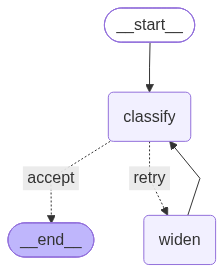

In [179]:
# ==========================================================
# Live intake check
# ==========================================================
# The graph first, then input validation, then the graph running, then a
# lookup into the crew plan.

from IPython.display import Image, display

display(Image("routing_graph.png"))


def route_and_check(message: str, month: int = 6):
    """Route a message and return the crew plan row for the department it goes to."""
    if not isinstance(message, str) or not message.strip():
        return {"status": "rejected", "reason": "empty message, no model call made"}
    if month not in range(1, 13):
        return {"status": "rejected", "reason": f"month {month} outside 1 to 12"}

    routed, attempts = classify_graph(message.strip())
    candidates = 8 * (3 ** (attempts - 1))
    path = ("accepted on the first pass" if attempts == 1
            else "first answer was not a known type, retrieval widened and ran again")

    if routed["department"] is None:
        return {
            "status": "unrouted",
            "message": message,
            "graph_attempts": attempts,
            "candidates_shown": candidates,
            "graph_path": path,
            "request_type": routed["request_type"],
            "action": "send to a human operator",
        }

    dept = routed["department"]
    row = plan_detail[(plan_detail["department"] == dept)
                      & (plan_detail["month"] == month)].iloc[0]
    return {
        "status": "routed",
        "message": message,
        "graph_attempts": attempts,
        "candidates_shown": candidates,
        "graph_path": path,
        "request_type": routed["request_type"],
        "queue": routed["queue"],
        "department": dept,
        "month": month,
        "forecast_demand": int(round(row["demand"])),
        "permanent_crews": int(row["crews"]),
        "seasonal_crews": int(row["seasonal_crews"]),
        "monthly_capacity": int(row["capacity"]),
        "spare_capacity": int(row["capacity"] - round(row["demand"])),
    }


pp(route_and_check("   "), title="empty message, rejected before any model call")

pp(route_and_check(
    "The rim on the basketball court is bent down at an angle and the net is gone.",
), title="no matching type, after the graph widened and tried again")

pp(route_and_check(
    "A large branch snapped off a tree in Ringer Park and is blocking the path.",
    month=6,
), title="June, a department with room")

pp(route_and_check(
    "There is a deep pothole on Centre St that has been there for weeks.",
    month=8,
), title="August, a department already over capacity")



---
**OBSERVATIONS:**

The 4 messages cover the 3 outcomes the assistant can produce. An empty message
is rejected before any model call. A message describing something the city has
no request type for is returned unrouted after the graph has widened retrieval
and tried again, rather than being forced into the nearest department. The
other 2 resolve to a type, a queue and a department, and then to the crew
position in the month they would be worked.

The August example returns a department already 3,393 requests beyond its
monthly capacity. Routing a request correctly does not create capacity for it.
That is the connection between the 2 halves of this notebook: the assistant
decides whose queue the work belongs in, and the crew plan decides whether
anyone is there to do it.

---